In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip install -q numpy pandas matplotlib scikit-learn opencv-python tqdm

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
import os
import requests

url = "https://dengpingfan.github.io/pages/COD.html"

response = requests.get(url, timeout=30)

print("COD10K page status:", response.status_code)
print("Page accessible:", response.ok)

COD10K page status: 200
Page accessible: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

zip_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    size_gb = os.path.getsize(zip_path) / (1024**3)
    print(f"File size: {size_gb:.2f} GB")

File exists: True
File size: 2.25 GB


In [ ]:
import os
import shutil
import time

source = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"
destination = "/content/COD10K-v3.zip"

print("Copying COD10K from Google Drive to Colab...")
start = time.time()

shutil.copy2(source, destination)

elapsed = time.time() - start
size_gb = os.path.getsize(destination) / (1024**3)

print(f"Copy complete: {size_gb:.2f} GB")
print(f"Time taken: {elapsed/60:.1f} minutes")

Copying COD10K from Google Drive to Colab...
Copy complete: 2.25 GB
Time taken: 1.2 minutes


In [ ]:
import zipfile
import os

zip_path = "/content/COD10K-v3.zip"
extract_path = "/content/COD10K"

print("Extracting COD10K...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete.")

Extracting COD10K...
Extraction complete.


In [ ]:
import os

for root, dirs, files in os.walk("/content/COD10K"):
    if files:
        print(root, "->", len(files), "files")

/content/COD10K/COD10K-v3 -> 1 files
/content/COD10K/COD10K-v3/Info -> 5 files
/content/COD10K/COD10K-v3/Train -> 2 files
/content/COD10K/COD10K-v3/Train/GT_Edge -> 6000 files
/content/COD10K/COD10K-v3/Train/Image -> 6000 files
/content/COD10K/COD10K-v3/Train/GT_Object -> 6000 files
/content/COD10K/COD10K-v3/Train/GT_Instance -> 6000 files
/content/COD10K/COD10K-v3/Test -> 2 files
/content/COD10K/COD10K-v3/Test/GT_Edge -> 4000 files
/content/COD10K/COD10K-v3/Test/Image -> 4000 files
/content/COD10K/COD10K-v3/Test/GT_Object -> 4000 files
/content/COD10K/COD10K-v3/Test/GT_Instance -> 4000 files


In [ ]:
import os
import glob

BASE_DIR = "/content/COD10K/COD10K-v3"

IMAGE_DIR = os.path.join(BASE_DIR, "Train", "Image")
MASK_DIR = os.path.join(BASE_DIR, "Train", "GT_Object")

image_files = sorted(
    glob.glob(os.path.join(IMAGE_DIR, "*"))
)

mask_files = sorted(
    glob.glob(os.path.join(MASK_DIR, "*"))
)

# Match images and masks by filename (without extension)
image_map = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in image_files
}

mask_map = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in mask_files
}

common_names = sorted(set(image_map) & set(mask_map))

print("Total training images:", len(image_files))
print("Total ground-truth masks:", len(mask_files))
print("Matched image-mask pairs:", len(common_names))
print("Unmatched images:", len(set(image_map) - set(mask_map)))
print("Unmatched masks:", len(set(mask_map) - set(image_map)))

print("\nSample matched filename:")
print(common_names[0] if common_names else "No matches found")

Total training images: 6000
Total ground-truth masks: 6000
Matched image-mask pairs: 6000
Unmatched images: 0
Unmatched masks: 0

Sample matched filename:
COD10K-CAM-1-Aquatic-1-BatFish-1


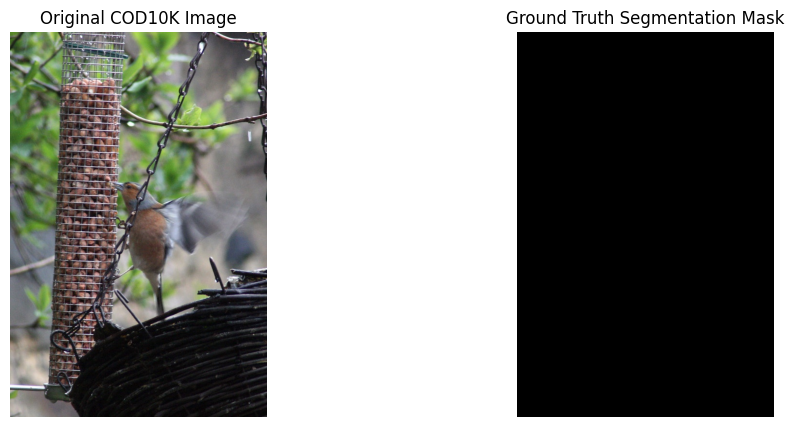

In [ ]:
import matplotlib.pyplot as plt
import random
from PIL import Image

sample_name = random.choice(common_names)

image_path = image_map[sample_name]
mask_path = mask_map[sample_name]

image = Image.open(image_path).convert("RGB")
mask = Image.open(mask_path).convert("L")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original COD10K Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Segmentation Mask")
plt.axis("off")

plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image

sample_name = common_names[0]
mask_path = mask_map[sample_name]

print("Mask filename:", os.path.basename(mask_path))
print("Mask file size:", os.path.getsize(mask_path), "bytes")

mask = np.array(Image.open(mask_path))

print("Image mode:", Image.open(mask_path).mode)
print("Mask shape:", mask.shape)
print("Minimum:", mask.min())
print("Maximum:", mask.max())
print("Unique values:", np.unique(mask)[:50])
print("Non-zero pixels:", np.count_nonzero(mask))
print("Total pixels:", mask.size)

Mask filename: COD10K-CAM-1-Aquatic-1-BatFish-1.png
Mask file size: 3000 bytes
Image mode: L
Mask shape: (600, 800)
Minimum: 0
Maximum: 255
Unique values: [  0 255]
Non-zero pixels: 48490
Total pixels: 480000


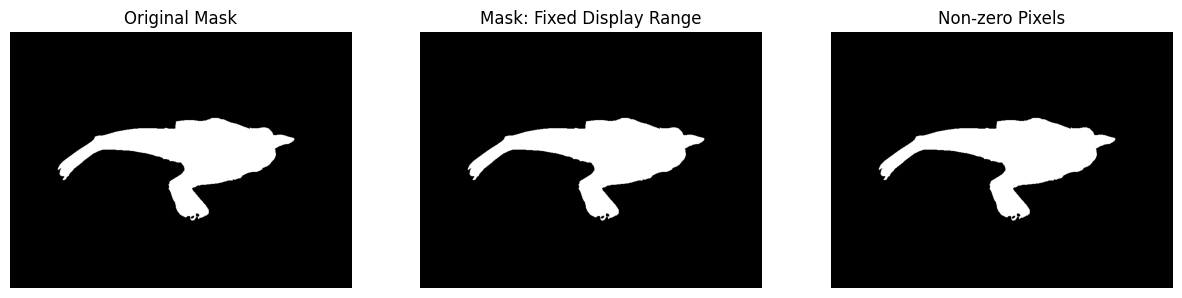

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray", vmin=0, vmax=255)
plt.title("Mask: Fixed Display Range")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask > 0, cmap="gray")
plt.title("Non-zero Pixels")
plt.axis("off")

plt.show()

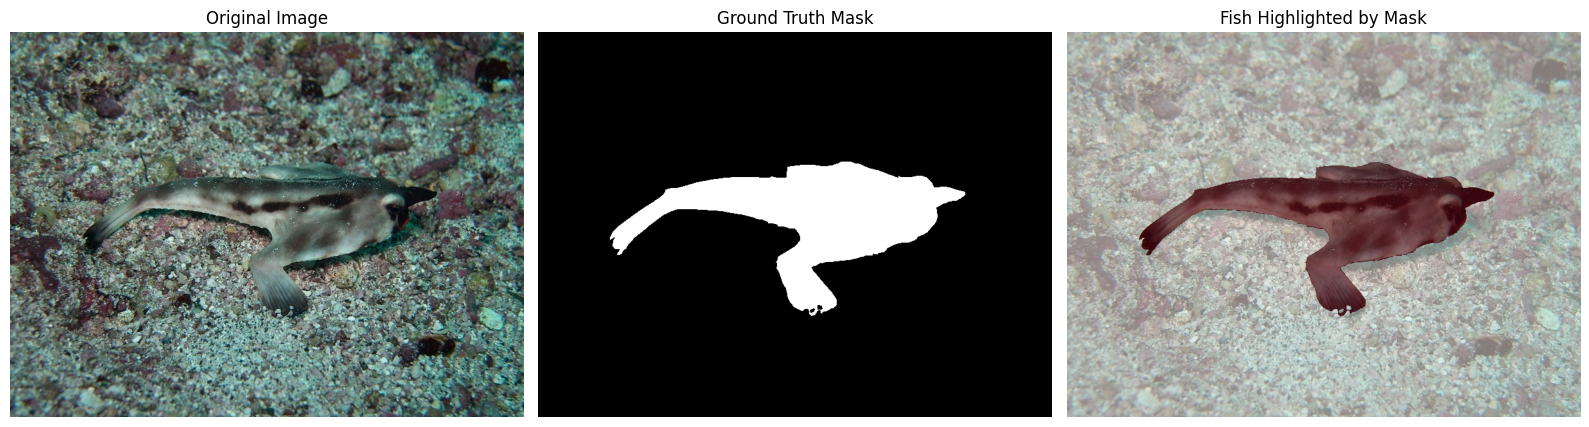

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image = np.array(Image.open(image_map[sample_name]).convert("RGB"))
mask = np.array(Image.open(mask_map[sample_name]).convert("L"))

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray", vmin=0, vmax=255)
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(mask, cmap="Reds", alpha=0.5)
plt.title("Fish Highlighted by Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

train_names, val_names = train_test_split(
    common_names,
    test_size=0.10,
    random_state=42,
    shuffle=True
)

print("Training samples:", len(train_names))
print("Validation samples:", len(val_names))

Training samples: 5400
Validation samples: 600


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

IMAGE_SIZE = 256

class COD10KDataset(Dataset):

    def __init__(self, names, image_map, mask_map):
        self.names = names
        self.image_map = image_map
        self.mask_map = mask_map

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):

        name = self.names[index]

        image = Image.open(
            self.image_map[name]
        ).convert("RGB")

        mask = Image.open(
            self.mask_map[name]
        ).convert("L")

        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.NEAREST
        )

        image = np.array(image, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32)

        mask = (mask > 127).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


train_dataset = COD10KDataset(
    train_names, image_map, mask_map
)

val_dataset = COD10KDataset(
    val_names, image_map, mask_map
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 5400
Validation dataset: 600


In [ ]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image values:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image values: 0.0 1.0
Mask values: tensor([0., 1.])


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(images[0].permute(1, 2, 0))
plt.title("Training Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masks[0, 0], cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

NameError: name 'train_dataset' is not defined

Minimum: 0.0
Maximum: 0.0
White pixels: 0
Black pixels: 65536


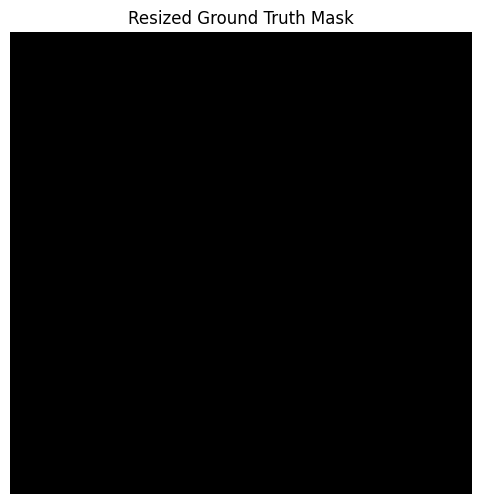

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

mask_sample = masks[0, 0].cpu().numpy()

print("Minimum:", mask_sample.min())
print("Maximum:", mask_sample.max())
print("White pixels:", np.sum(mask_sample == 1))
print("Black pixels:", np.sum(mask_sample == 0))

plt.figure(figsize=(6, 6))
plt.imshow(mask_sample, cmap="gray", vmin=0, vmax=1)
plt.title("Resized Ground Truth Mask")
plt.axis("off")
plt.show()

Mask name: COD10K-CAM-1-Aquatic-15-SeaHorse-1008
Original mask size: (1024, 683)
Original mask values: [  0 255]


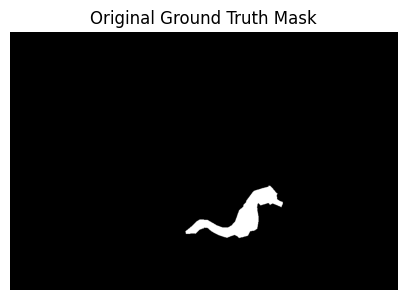

In [ ]:
sample_name = train_names[0]
mask_path = mask_map[sample_name]

original_mask = Image.open(mask_path).convert("L")

print("Mask name:", sample_name)
print("Original mask size:", original_mask.size)
print("Original mask values:", np.unique(np.array(original_mask)))

plt.figure(figsize=(5, 5))
plt.imshow(original_mask, cmap="gray")
plt.title("Original Ground Truth Mask")
plt.axis("off")
plt.show()

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Mask minimum: 0.0
Mask maximum: 1.0
White pixels: 996


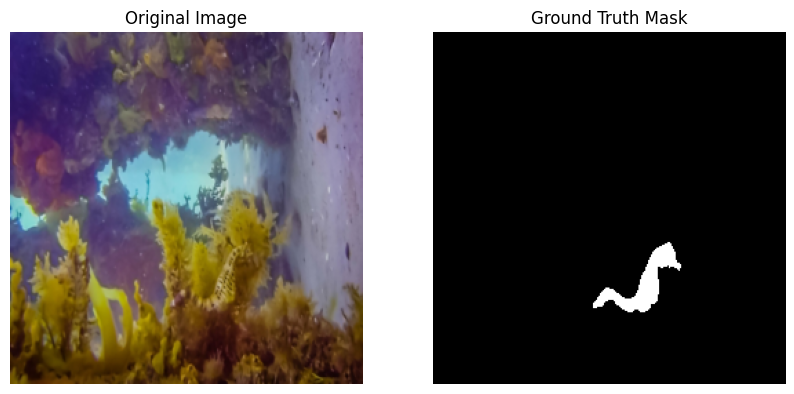

In [ ]:
image_tensor, mask_tensor = train_dataset[0]

print("Image shape:", image_tensor.shape)
print("Mask shape:", mask_tensor.shape)
print("Mask minimum:", mask_tensor.min().item())
print("Mask maximum:", mask_tensor.max().item())
print("White pixels:", (mask_tensor == 1).sum().item())

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_tensor.permute(1, 2, 0))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_tensor.squeeze(0), cmap="gray", vmin=0, vmax=1)
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
    print("Using CPU")

CUDA available: True
GPU: Tesla T4


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with skip connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


model = UNet().to(device)

print("U-Net model created successfully!")
print("Device:", device)

U-Net model created successfully!
Device: cuda


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch imports successful!")
print("GPU available:", torch.cuda.is_available())

PyTorch imports successful!
GPU available: True


In [ ]:
sample_input = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    sample_output = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)

Input shape: torch.Size([1, 3, 256, 256])
Output shape: torch.Size([1, 1, 256, 256])


In [ ]:
def dice_loss(predictions, targets, smooth=1.0):
    predictions = torch.sigmoid(predictions)

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    intersection = (predictions * targets).sum()

    dice = (2.0 * intersection + smooth) / (
        predictions.sum() + targets.sum() + smooth
    )

    return 1.0 - dice


# Test Dice Loss
sample_input = torch.randn(2, 3, 256, 256).to(device)
sample_target = torch.randint(
    0, 2, (2, 1, 256, 256)
).float().to(device)

with torch.no_grad():
    sample_prediction = model(sample_input)
    loss = dice_loss(sample_prediction, sample_target)

print("Dice Loss:", loss.item())

Dice Loss: 0.4991459250450134


In [ ]:
EPOCHS = 5
LEARNING_RATE = 0.001

criterion = dice_loss

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Training configuration ready!")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss function: Dice Loss")
print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training configuration ready!
Epochs: 5
Learning rate: 0.001
Optimizer: Adam
Loss function: Dice Loss
Device: cuda
Training batches: 675
Validation batches: 75


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 675
Validation batches: 75


In [ ]:
import os

BASE_DIR = "/content/COD10K/COD10K-v3"

IMAGE_DIR = os.path.join(BASE_DIR, "Train", "Image")
MASK_DIR = os.path.join(BASE_DIR, "Train", "GT_Object")

print("Image folder exists:", os.path.exists(IMAGE_DIR))
print("Mask folder exists:", os.path.exists(MASK_DIR))

Image folder exists: False
Mask folder exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"

print("ZIP file exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print("ZIP size (GB):", round(os.path.getsize(ZIP_PATH) / (1024**3), 2))

ZIP file exists: True
ZIP size (GB): 2.25


In [ ]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"
EXTRACT_PATH = "/content/COD10K"

os.makedirs(EXTRACT_PATH, exist_ok=True)

print("Extracting COD10K dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Extraction completed!")

Extracting COD10K dataset...
Extraction completed!


In [ ]:
BASE_DIR = "/content/COD10K/COD10K-v3"

IMAGE_DIR = os.path.join(BASE_DIR, "Train", "Image")
MASK_DIR = os.path.join(BASE_DIR, "Train", "GT_Object")

print("Image folder exists:", os.path.exists(IMAGE_DIR))
print("Mask folder exists:", os.path.exists(MASK_DIR))

Image folder exists: True
Mask folder exists: True


In [ ]:
import glob
import os

image_files = sorted(glob.glob(os.path.join(IMAGE_DIR, "*")))
mask_files = sorted(glob.glob(os.path.join(MASK_DIR, "*")))

image_map = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in image_files
}

mask_map = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in mask_files
}

common_names = sorted(set(image_map) & set(mask_map))

print("Total images:", len(image_files))
print("Total masks:", len(mask_files))
print("Matched pairs:", len(common_names))

Total images: 6000
Total masks: 6000
Matched pairs: 6000


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 675
Validation batches: 75


In [ ]:
print("GPU available:", torch.cuda.is_available())
print("Device:", device)
print("Model loaded:", model is not None)

GPU available: True
Device: cuda
Model loaded: True


In [ ]:
# Check and recreate model if necessary

if "model" not in globals():
    model = UNet().to(device)

# Set training configuration
EPOCHS = 5
LEARNING_RATE = 0.001

criterion = dice_loss

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Model ready:", model is not None)
print("GPU:", torch.cuda.get_device_name(0))
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Model ready: True
GPU: Tesla T4
Epochs: 5
Learning rate: 0.001
Training batches: 675
Validation batches: 75


In [ ]:
from tqdm.auto import tqdm
import torch
import os

EPOCHS = 5
best_val_loss = float("inf")

os.makedirs("/content/models", exist_ok=True)

for epoch in range(EPOCHS):

    # Training phase
    model.train()
    train_loss = 0.0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} - Training")

    for images, masks in train_bar:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = train_loss / len(train_loader)

    # Validation phase
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc="Validation"):
            images = images.to(device)
            masks = masks.to(device)

            predictions = model(images)
            loss = criterion(predictions, masks)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Training Loss: {avg_train_loss:.4f}")
    print(f"Validation Loss: {avg_val_loss:.4f}")

    # Save best checkpoint
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "/content/models/unet_cod10k_best.pth"
        )

        print("Best model checkpoint saved!")

print("\nTraining completed!")

Epoch 1/5 - Training:   0%|          | 0/675 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 1/5
Training Loss: 0.7976
Validation Loss: 0.7996
Best model checkpoint saved!


Epoch 2/5 - Training:   0%|          | 0/675 [00:00<?, ?it/s]

Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 2/5
Training Loss: 0.7438
Validation Loss: 0.6966
Best model checkpoint saved!


... (7 outputs left out)

Epoch 5/5 - Training:   0%|          | 0/675 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7887f74b8900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7887f74b8900>
AssertionErrorTraceback (most recent call last):
: Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
can only test a child process<function _MultiProcessingDataLoaderIter.__del__ at 0x7887f74b8900>    

self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/pyt

Validation:   0%|          | 0/75 [00:00<?, ?it/s]


Epoch 5/5
Training Loss: 0.7187
Validation Loss: 0.8629

Training completed!


In [ ]:
import os

checkpoint = "/content/models/unet_cod10k_best.pth"

print("Checkpoint exists:", os.path.exists(checkpoint))

if os.path.exists(checkpoint):
    print(
        "Checkpoint size (MB):",
        round(os.path.getsize(checkpoint) / (1024**2), 2)
    )

print("Best validation loss:", best_val_loss)

Checkpoint exists: True
Checkpoint size (MB): 29.69
Best validation loss: 0.693297533194224


In [ ]:
!pip install -q pysodmetrics

In [ ]:
import torch
import os

# Load the best-performing model from epoch 3
model.load_state_dict(
    torch.load(
        "/content/models/unet_cod10k_best.pth",
        map_location=device
    )
)

model.to(device)
model.eval()

print("Best U-Net checkpoint loaded successfully!")
print("Evaluation device:", device)

Best U-Net checkpoint loaded successfully!
Evaluation device: cuda


In [ ]:
val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Validation samples:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation samples: 600
Validation batches: 75


In [ ]:
try:
    import py_sod_metrics
    print("PySODMetrics imported successfully!")
except ImportError:
    print("Installing PySODMetrics...")
    !pip install -q py_sod_metrics
    import py_sod_metrics
    print("PySODMetrics installed successfully!")

PySODMetrics imported successfully!


In [ ]:
import torch
import numpy as np
import pandas as pd
import cv2
import os

from tqdm.auto import tqdm
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

# Load the best checkpoint (Epoch 3)
model.load_state_dict(
    torch.load(
        "/content/models/unet_cod10k_best.pth",
        map_location=device
    )
)
model.eval()

# Initialize evaluation metrics
mae_metric = MAE()
em_metric = Emeasure()
sm_metric = Smeasure()
wfm_metric = WeightedFmeasure()

# Evaluate validation dataset
cursor = 0

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating COD10K"):

        images = images.to(device)

        predictions = torch.sigmoid(model(images))
        predictions = predictions.cpu().numpy()

        for i in range(len(images)):

            name = val_names[cursor]
            cursor += 1

            # Prediction: convert to grayscale uint8
            pred = predictions[i, 0]
            pred = (pred * 255).clip(0, 255).astype(np.uint8)

            # Load original ground-truth mask
            gt = cv2.imread(
                mask_map[name],
                cv2.IMREAD_GRAYSCALE
            )

            # Resize prediction to original mask dimensions
            pred = cv2.resize(
                pred,
                (gt.shape[1], gt.shape[0]),
                interpolation=cv2.INTER_LINEAR
            )

            # Update metrics
            mae_metric.step(pred, gt)
            em_metric.step(pred, gt)
            sm_metric.step(pred, gt)
            wfm_metric.step(pred, gt)

# Collect final results
mae_score = mae_metric.get_results()["mae"]
em_score = em_metric.get_results()["em"]["curve"].max()
sm_score = sm_metric.get_results()["sm"]
wfm_score = wfm_metric.get_results()["wfm"]

results = pd.DataFrame([{
    "S-measure": sm_score,
    "E-measure (Max)": em_score,
    "Weighted F-measure": wfm_score,
    "MAE": mae_score
}])

# Save metrics CSV
os.makedirs("/content/results", exist_ok=True)

csv_path = "/content/results/cod10k_metrics.csv"
results.to_csv(csv_path, index=False)

print("\nCOD10K Validation Results")
display(results)

print("\nMetrics saved to:", csv_path)

Evaluating COD10K:   0%|          | 0/75 [00:00<?, ?it/s]


COD10K Validation Results


,S-measure,E-measure (Max),Weighted F-measure,MAE
0,0.736647,0.779339,0.131963,0.085046



Metrics saved to: /content/results/cod10k_metrics.csv


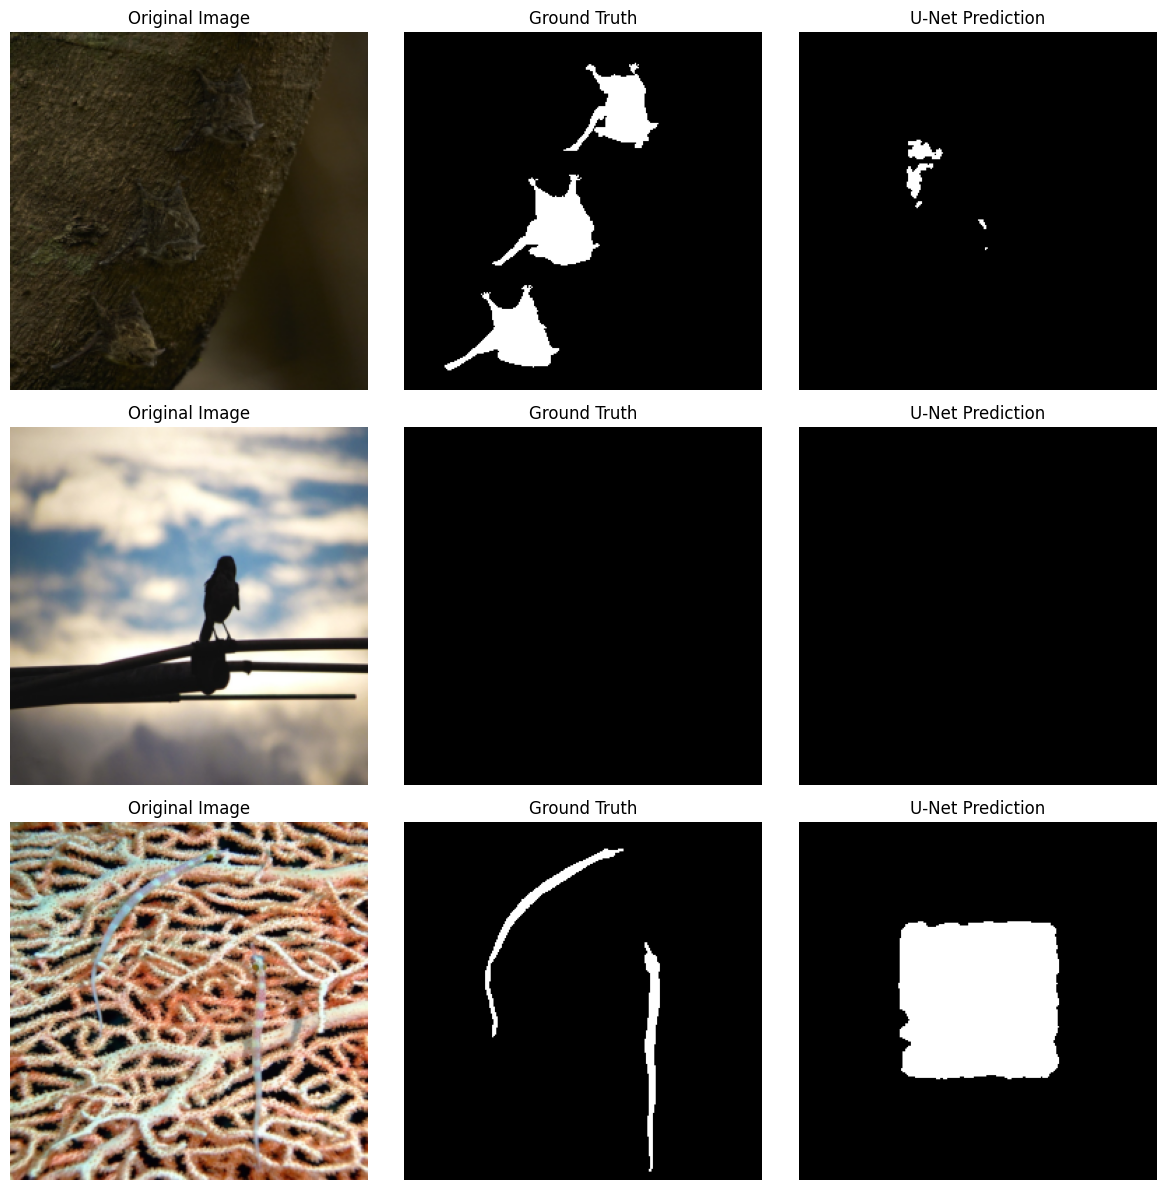

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

with torch.no_grad():
    for i in range(3):
        image, mask = val_dataset[i]

        prediction = model(
            image.unsqueeze(0).to(device)
        )

        prediction = torch.sigmoid(prediction).squeeze().cpu().numpy()
        prediction = (prediction > 0.5).astype(np.uint8)

        axes[i, 0].imshow(image.permute(1, 2, 0))
        axes[i, 0].set_title("Original Image")

        axes[i, 1].imshow(mask.squeeze(), cmap="gray")
        axes[i, 1].set_title("Ground Truth")

        axes[i, 2].imshow(prediction, cmap="gray")
        axes[i, 2].set_title("U-Net Prediction")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.savefig("/content/cod10k_predictions.png", dpi=150)
plt.show()

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Mask minimum: 0.0
Mask maximum: 0.0
White pixels: 0


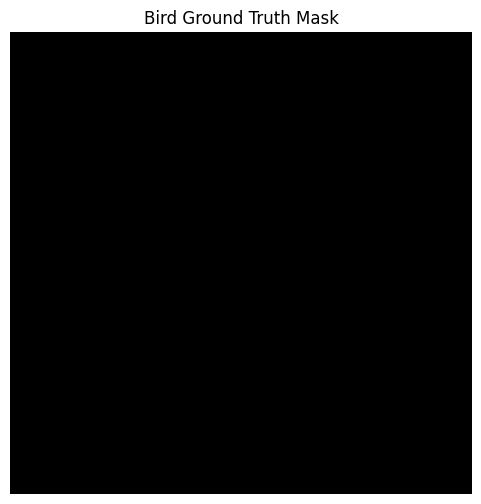

In [ ]:
# Inspect the second validation sample
image, mask = val_dataset[1]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask minimum:", mask.min().item())
print("Mask maximum:", mask.max().item())
print("White pixels:", (mask == 1).sum().item())

plt.figure(figsize=(6, 6))
plt.imshow(mask.squeeze(), cmap="gray", vmin=0, vmax=1)
plt.title("Bird Ground Truth Mask")
plt.axis("off")
plt.show()

In [ ]:
sample_name = val_names[1]
sample_mask_path = mask_map[sample_name]

print("Image name:", sample_name)
print("Mask path:", sample_mask_path)
print("Original mask values:",
      np.unique(np.array(Image.open(sample_mask_path).convert("L"))))

Image name: COD10K-NonCAM-3-Flying-1517
Mask path: /content/COD10K/COD10K-v3/Train/GT_Object/COD10K-NonCAM-3-Flying-1517.png
Original mask values: [0]


In [ ]:
cam_count = sum("COD10K-CAM-" in name for name in common_names)
noncam_count = sum("COD10K-NonCAM-" in name for name in common_names)

print("CAM images:", cam_count)
print("NonCAM images:", noncam_count)
print("Total:", len(common_names))

CAM images: 3040
NonCAM images: 2960
Total: 6000


In [ ]:
import os

DATA_ROOT = "/content/COD10K/COD10K-v3"

print("Dataset exists:", os.path.exists(DATA_ROOT))
print("Train images:", os.path.exists(f"{DATA_ROOT}/Train/Image"))
print("Train masks:", os.path.exists(f"{DATA_ROOT}/Train/GT_Object"))

Dataset exists: True
Train images: True
Train masks: True


In [ ]:
import os

IMAGE_DIR = "/content/COD10K/COD10K-v3/Train/Image"
MASK_DIR = "/content/COD10K/COD10K-v3/Train/GT_Object"

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

mask_files = sorted([
    f for f in os.listdir(MASK_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Match images and masks using filename without extension
image_map = {
    os.path.splitext(f)[0]: os.path.join(IMAGE_DIR, f)
    for f in image_files
}

mask_map = {
    os.path.splitext(f)[0]: os.path.join(MASK_DIR, f)
    for f in mask_files
}

common_names = sorted(set(image_map) & set(mask_map))

print("Images:", len(image_files))
print("Masks:", len(mask_files))
print("Matched pairs:", len(common_names))

Images: 6000
Masks: 6000
Matched pairs: 6000


In [ ]:
from sklearn.model_selection import train_test_split

train_names, val_names = train_test_split(
    common_names,
    test_size=0.10,
    random_state=42,
    shuffle=True
)

print("Training images:", len(train_names))
print("Validation images:", len(val_names))
print("Validation sample:", val_names[1])

Training images: 5400
Validation images: 600
Validation sample: COD10K-NonCAM-3-Flying-1517


In [ ]:
cam_train = sum("COD10K-CAM-" in name for name in train_names)
noncam_train = sum("COD10K-NonCAM-" in name for name in train_names)

cam_val = sum("COD10K-CAM-" in name for name in val_names)
noncam_val = sum("COD10K-NonCAM-" in name for name in val_names)

print("CAM training:", cam_train)
print("NonCAM training:", noncam_train)
print("CAM validation:", cam_val)
print("NonCAM validation:", noncam_val)

CAM training: 2723
NonCAM training: 2677
CAM validation: 317
NonCAM validation: 283


CAM validation index: 0
CAM image name: COD10K-CAM-3-Flying-50-Bat-2961
Ground-truth white pixels: 5891
Predicted white pixels: 8007
Prediction probability min: 1.8131363e-08
Prediction probability max: 1.0
Prediction probability mean: 0.122626126


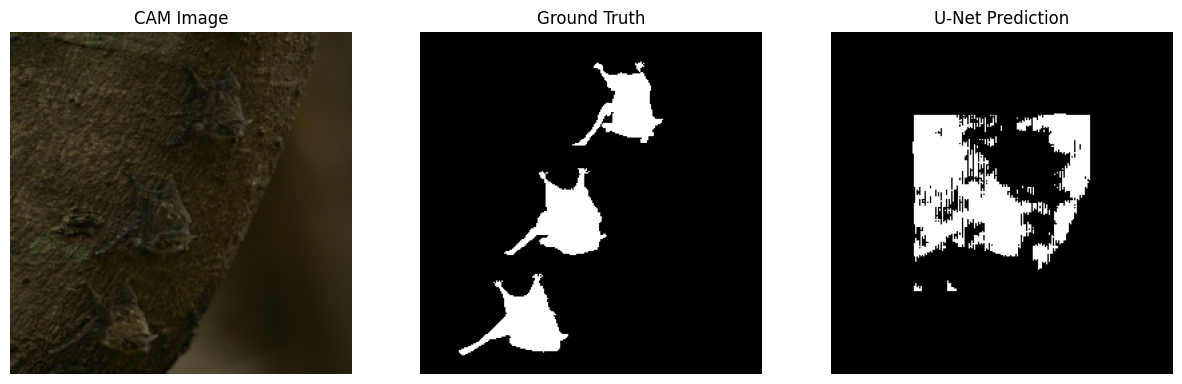

In [ ]:
# Find the first CAM image in the validation set
cam_index = next(
    i for i, name in enumerate(val_names)
    if "COD10K-CAM-" in name
)

print("CAM validation index:", cam_index)
print("CAM image name:", val_names[cam_index])

image, mask = val_dataset[cam_index]

model.eval()

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
    probability = torch.sigmoid(output).squeeze().cpu().numpy()

prediction = (probability > 0.5).astype("float32")

print("Ground-truth white pixels:", int(mask.sum().item()))
print("Predicted white pixels:", int(prediction.sum()))
print("Prediction probability min:", probability.min())
print("Prediction probability max:", probability.max())
print("Prediction probability mean:", probability.mean())

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title("CAM Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask.squeeze(), cmap="gray", vmin=0, vmax=1)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="gray", vmin=0, vmax=1)
plt.title("U-Net Prediction")
plt.axis("off")

plt.show()

In [ ]:
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

IMAGE_SIZE = 256

class COD10KDataset(Dataset):
    def __init__(self, names, image_map, mask_map):
        self.names = names
        self.image_map = image_map
        self.mask_map = mask_map

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]

        image = Image.open(self.image_map[name]).convert("RGB")
        mask = Image.open(self.mask_map[name]).convert("L")

        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.NEAREST
        )

        image = np.array(image, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32)

        mask = (mask > 127).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

val_dataset = COD10KDataset(
    val_names,
    image_map,
    mask_map
)

print("Validation dataset created:", len(val_dataset))

Validation dataset created: 600


Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Ground-truth white pixels: 5891


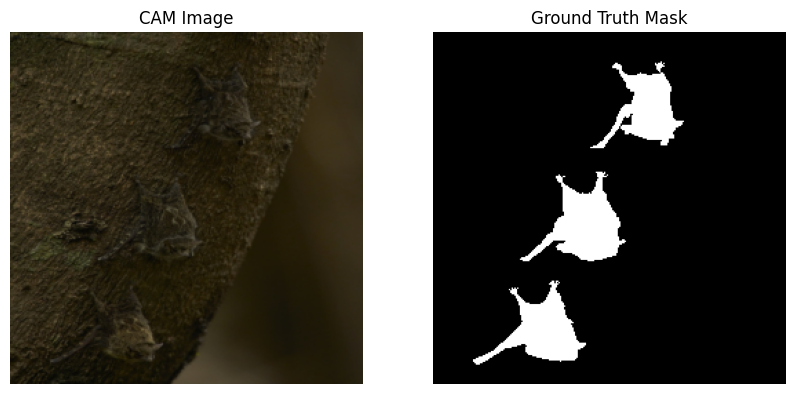

In [ ]:
image, mask = val_dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Ground-truth white pixels:", int(mask.sum().item()))

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title("CAM Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.squeeze(), cmap="gray", vmin=0, vmax=1)
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


model = UNet().to(device)

print("Device:", device)
print("U-Net recreated successfully.")

Device: cuda
U-Net recreated successfully.


In [ ]:
import os

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".pth"):
            matches.append(os.path.join(root, file))

print("Checkpoint files found:")

for path in matches:
    print(path)

Checkpoint files found:


In [ ]:
import os

DRIVE_MODEL_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/models"
os.makedirs(DRIVE_MODEL_DIR, exist_ok=True)

print("Model folder ready:")
print(DRIVE_MODEL_DIR)

Model folder ready:
/content/drive/MyDrive/Colab Notebooks/COD10K/models


In [ ]:
from torch.utils.data import DataLoader

train_dataset = COD10KDataset(
    train_names,
    image_map,
    mask_map
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Training dataset:", len(train_dataset))
print("Training batches:", len(train_loader))

Training dataset: 5400
Training batches: 675


In [ ]:
def dice_loss(predictions, targets, smooth=1.0):
    predictions = torch.sigmoid(predictions)

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    intersection = (predictions * targets).sum()

    dice = (
        (2.0 * intersection + smooth)
        /
        (predictions.sum() + targets.sum() + smooth)
    )

    return 1.0 - dice


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Dice loss ready.")
print("Adam optimizer ready.")

Dice loss ready.
Adam optimizer ready.


In [ ]:
val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Validation dataset:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation dataset: 600
Validation batches: 75


In [ ]:
import os
import torch

EPOCHS = 5

DRIVE_CHECKPOINT = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "COD10K/models/unet_cod10k_best.pth"
)

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = dice_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)

            loss = dice_loss(outputs, masks)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # -------------------------
    # Save best model
    # -------------------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            DRIVE_CHECKPOINT
        )

        print("  ✓ Best model saved to Google Drive")

print("\nTraining complete.")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", DRIVE_CHECKPOINT)

Epoch 1/5 | Train Loss: 0.8071 | Val Loss: 0.7362
  ✓ Best model saved to Google Drive
Epoch 2/5 | Train Loss: 0.7537 | Val Loss: 0.7850
Epoch 3/5 | Train Loss: 0.7403 | Val Loss: 0.7365
Epoch 4/5 | Train Loss: 0.7419 | Val Loss: 0.7275
  ✓ Best model saved to Google Drive
Epoch 5/5 | Train Loss: 0.7337 | Val Loss: 0.7403

Training complete.
Best validation loss: 0.7274939823150635
Checkpoint: /content/drive/MyDrive/Colab Notebooks/COD10K/models/unet_cod10k_best.pth


In [ ]:
import os

print("Checkpoint exists:", os.path.exists(DRIVE_CHECKPOINT))

if os.path.exists(DRIVE_CHECKPOINT):
    size_mb = os.path.getsize(DRIVE_CHECKPOINT) / (1024 * 1024)
    print(f"Checkpoint size: {size_mb:.2f} MB")

Checkpoint exists: True
Checkpoint size: 29.69 MB


In [ ]:
model.load_state_dict(
    torch.load(DRIVE_CHECKPOINT, map_location=device)
)

model.to(device)
model.eval()

print("Best Epoch 4 model loaded successfully.")

Best Epoch 4 model loaded successfully.


Ground-truth white pixels: 5891
Predicted white pixels: 8007
Prediction probability: 1.8131363e-08 to 1.0


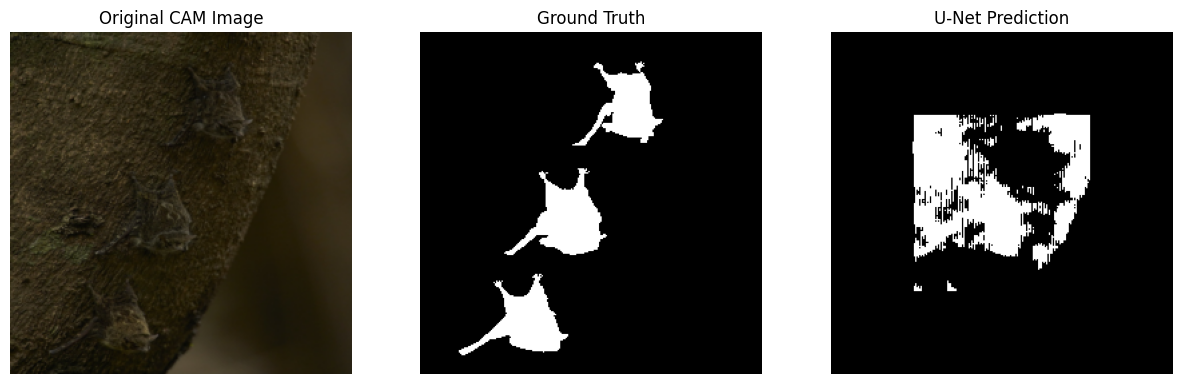

In [ ]:
import matplotlib.pyplot as plt
import torch

image, mask = val_dataset[0]

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
    probability = torch.sigmoid(output).squeeze().cpu().numpy()

prediction = (probability > 0.5).astype("float32")

print("Ground-truth white pixels:", int(mask.sum().item()))
print("Predicted white pixels:", int(prediction.sum()))
print("Prediction probability:", probability.min(), "to", probability.max())

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title("Original CAM Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask.squeeze(), cmap="gray", vmin=0, vmax=1)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="gray", vmin=0, vmax=1)
plt.title("U-Net Prediction")
plt.axis("off")

plt.show()

In [ ]:
!pip install pysodmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 109.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 69.6 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 5.0.0.93
    Uninstalling opencv-python-headless-5.0.0.93:
      Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pysodmetrics]


In [ ]:
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

print("All four evaluation metrics imported successfully!")

All four evaluation metrics imported successfully!


In [ ]:
import cv2
import numpy as np
from PIL import Image
from py_sod_metrics import MAE, Emeasure, Smeasure, WeightedFmeasure

mae_metric = MAE()
em_metric = Emeasure()
sm_metric = Smeasure()
wfm_metric = WeightedFmeasure()

print("S-measure ready")
print("E-measure ready")
print("Weighted F-measure ready")
print("MAE ready")

S-measure ready
E-measure ready
Weighted F-measure ready
MAE ready


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch

# Reset metric objects
mae_metric = MAE()
em_metric = Emeasure()
sm_metric = Smeasure()
wfm_metric = WeightedFmeasure()

model.eval()
image_index = 0

with torch.no_grad():
    for images, masks in val_loader:

        images = images.to(device)
        outputs = model(images)
        probabilities = torch.sigmoid(outputs).cpu().numpy()

        for j in range(len(images)):

            name = val_names[image_index]

            # Predicted probability map
            pred = (probabilities[j, 0] * 255).astype(np.uint8)

            # Load original ground-truth mask
            gt_path = mask_map[name]
            gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)

            # Resize prediction to original mask dimensions
            pred = cv2.resize(
                pred,
                (gt.shape[1], gt.shape[0]),
                interpolation=cv2.INTER_LINEAR
            )

            # Calculate metrics
            mae_metric.step(pred, gt)
            em_metric.step(pred, gt)
            sm_metric.step(pred, gt)
            wfm_metric.step(pred, gt)

            image_index += 1

print("Evaluation completed!")
print("Images evaluated:", image_index)

Evaluation completed!
Images evaluated: 600


In [ ]:
s_measure = sm_metric.get_results()["sm"]
e_measure = em_metric.get_results()["em"]["curve"].max()
weighted_f = wfm_metric.get_results()["wfm"]
mae = mae_metric.get_results()["mae"]

results_df = pd.DataFrame({
    "Metric": [
        "S-measure",
        "E-measure (Max)",
        "Weighted F-measure",
        "MAE"
    ],
    "Value": [
        s_measure,
        e_measure,
        weighted_f,
        mae
    ]
})

print("Final COD10K Evaluation Results")
display(results_df)

Final COD10K Evaluation Results


,Metric,Value
0,S-measure,0.680739
1,E-measure (Max),0.746016
2,Weighted F-measure,0.132105
3,MAE,0.163230


In [ ]:
import os

DRIVE_RESULTS_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "COD10K/results"
)

os.makedirs(DRIVE_RESULTS_DIR, exist_ok=True)

CSV_PATH = os.path.join(
    DRIVE_RESULTS_DIR,
    "cod10k_metrics.csv"
)

results_df.to_csv(CSV_PATH, index=False)

print("Metrics CSV saved successfully!")
print("Location:", CSV_PATH)

display(results_df)

Metrics CSV saved successfully!
Location: /content/drive/MyDrive/Colab Notebooks/COD10K/results/cod10k_metrics.csv


,Metric,Value
0,S-measure,0.680739
1,E-measure (Max),0.746016
2,Weighted F-measure,0.132105
3,MAE,0.163230


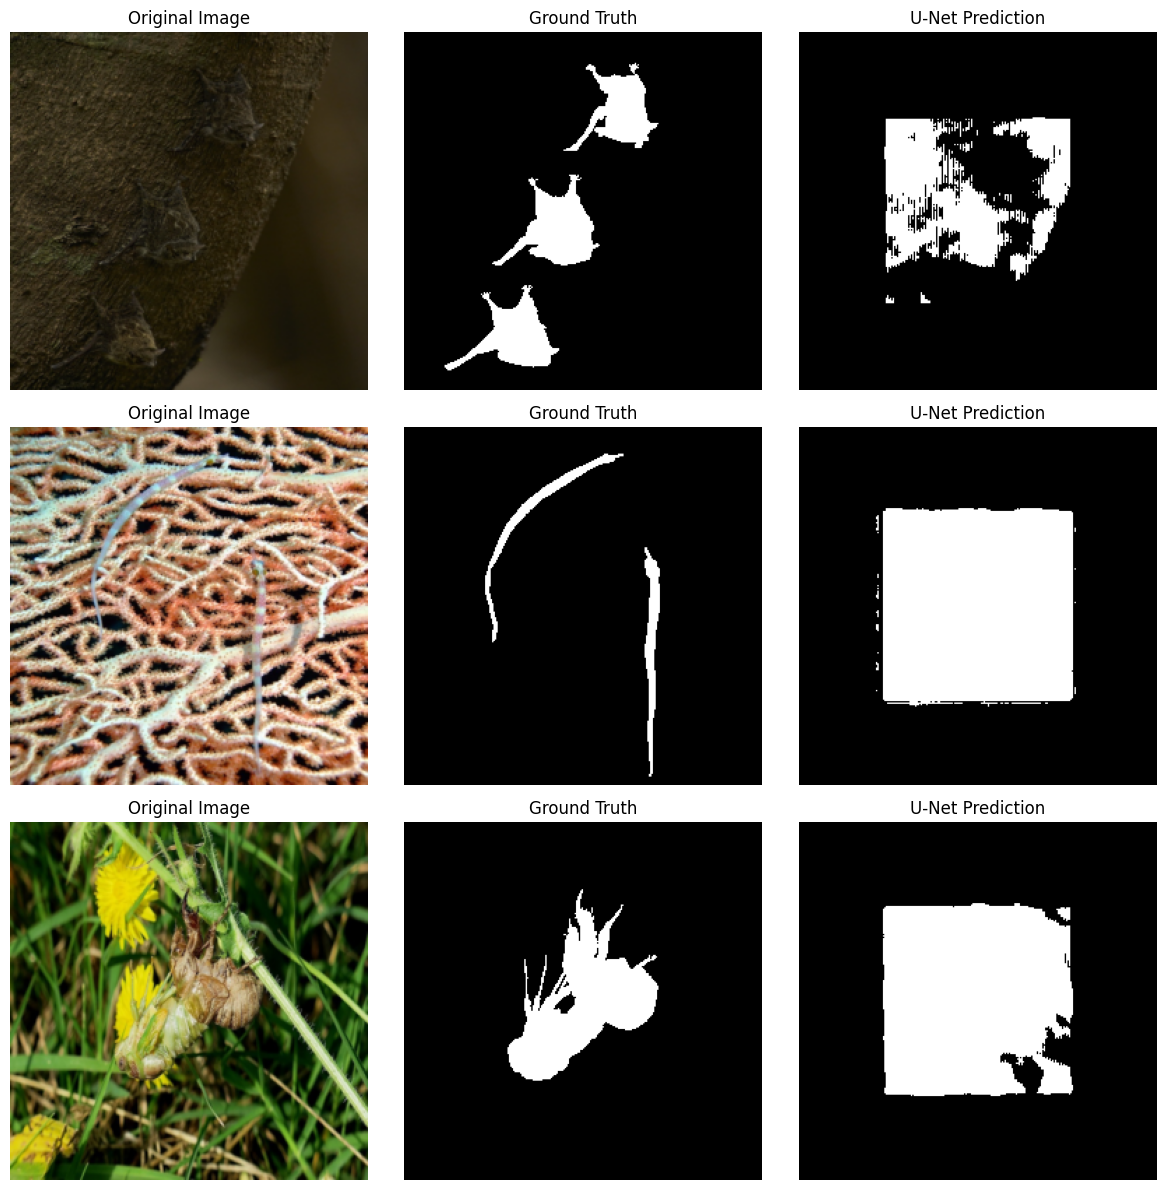

Prediction image saved: /content/drive/MyDrive/Colab Notebooks/COD10K/outputs/sample_predictions.png


In [ ]:
import os
import matplotlib.pyplot as plt
import torch

OUTPUT_DIR = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "COD10K/outputs"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Find three CAM validation images
cam_indices = [
    i for i, name in enumerate(val_names)
    if "COD10K-CAM-" in name
][:3]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

model.eval()

with torch.no_grad():
    for row, index in enumerate(cam_indices):

        image, mask = val_dataset[index]

        output = model(image.unsqueeze(0).to(device))
        probability = torch.sigmoid(output).squeeze().cpu().numpy()

        prediction = (probability > 0.5).astype("float32")

        axes[row, 0].imshow(image.permute(1, 2, 0))
        axes[row, 0].set_title("Original Image")

        axes[row, 1].imshow(mask.squeeze(), cmap="gray")
        axes[row, 1].set_title("Ground Truth")

        axes[row, 2].imshow(prediction, cmap="gray")
        axes[row, 2].set_title("U-Net Prediction")

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()

PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "sample_predictions.png"
)

plt.savefig(PREDICTION_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Prediction image saved:", PREDICTION_PATH)

In [ ]:
import os

files_to_check = {
    "Best U-Net Model": "/content/drive/MyDrive/Colab Notebooks/COD10K/models/unet_cod10k_best.pth",
    "Metrics CSV": "/content/drive/MyDrive/Colab Notebooks/COD10K/results/cod10k_metrics.csv",
    "Sample Predictions": "/content/drive/MyDrive/Colab Notebooks/COD10K/outputs/sample_predictions.png"
}

for name, path in files_to_check.items():
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✅ {name}: Saved ({size_mb:.2f} MB)")
    else:
        print(f"❌ {name}: Not found")

✅ Best U-Net Model: Saved (29.69 MB)
✅ Metrics CSV: Saved (0.00 MB)
✅ Sample Predictions: Saved (1.51 MB)


In [ ]:
!pip install -q timm gradio pysodmetrics opencv-python

In [ ]:
import torch
import timm
import gradio as gr
import cv2
import numpy as np
from PIL import Image

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
timm: 1.0.31
CUDA available: True


In [ ]:
import os

dataset_path = "/content/COD10K/COD10K-v3"

print("Dataset exists:", os.path.exists(dataset_path))
print("Dataset folders:", os.listdir(dataset_path) if os.path.exists(dataset_path) else "Not found")

Dataset exists: False
Dataset folders: Not found


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/drive/MyDrive/Colab Notebooks/COD10K"

print("COD10K folder exists:", os.path.exists(base_path))
print("Contents:", os.listdir(base_path) if os.path.exists(base_path) else "Not found")

COD10K folder exists: True
Contents: ['COD10K-v3.zip', 'models', 'results', 'outputs']


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"
extract_path = "/content/COD10K"

if not os.path.exists(extract_path):
    os.makedirs(extract_path)

print("Extracting COD10K...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete.")
print("Contents:", os.listdir(extract_path))

Extracting COD10K...
Extraction complete.
Contents: ['COD10K-v3']


In [ ]:
dataset_path = "/content/COD10K/COD10K-v3"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Dataset contents:", os.listdir(dataset_path))

Dataset exists: True
Dataset contents: ['Info', 'Test', 'Train', 'Readme.txt']


In [ ]:
import os

image_dir = "/content/COD10K/COD10K-v3/Train/Image"
mask_dir = "/content/COD10K/COD10K-v3/Train/GT_Object"

print("Training images:", len(os.listdir(image_dir)))
print("Training masks:", len(os.listdir(mask_dir)))
print("First image:", os.listdir(image_dir)[:3])
print("First mask:", os.listdir(mask_dir)[:3])

Training images: 6000
Training masks: 6000
First image: ['COD10K-NonCAM-3-Flying-1489.jpg', 'COD10K-CAM-3-Flying-61-Katydid-4199.jpg', 'COD10K-CAM-3-Flying-59-Grasshopper-3861.jpg']
First mask: ['COD10K-NonCAM-3-Flying-1787.png', 'COD10K-CAM-3-Flying-53-Bird-3033.png', 'COD10K-NonCAM-5-Background-1-Indoor-3094.png']


In [ ]:
import os
import random
import numpy as np

image_dir = "/content/COD10K/COD10K-v3/Train/Image"
mask_dir = "/content/COD10K/COD10K-v3/Train/GT_Object"

images = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

masks = sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Images:", len(images))
print("Masks:", len(masks))

# Use a fixed seed for reproducibility
random.seed(42)

indices = list(range(len(images)))
random.shuffle(indices)

train_size = int(0.90 * len(indices))

train_indices = indices[:train_size]
val_indices = indices[train_size:]

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Images: 6000
Masks: 6000
Training samples: 5400
Validation samples: 600


In [ ]:
import os
import re

image_dir = "/content/COD10K/COD10K-v3/Train/Image"
mask_dir = "/content/COD10K/COD10K-v3/Train/GT_Object"

def get_cod10k_id(filename):
    """
    Extract the final numeric ID from a COD10K filename.
    Example:
    COD10K-CAM-3-Flying-61-Katydid-4199.jpg -> 4199
    """
    match = re.search(r"-(\d+)\.(?:jpg|jpeg|png)$", filename, re.IGNORECASE)
    return match.group(1) if match else None

image_map = {}
mask_map = {}

for filename in os.listdir(image_dir):
    file_id = get_cod10k_id(filename)
    if file_id:
        image_map[file_id] = filename

for filename in os.listdir(mask_dir):
    file_id = get_cod10k_id(filename)
    if file_id:
        mask_map[file_id] = filename

common_ids = sorted(set(image_map.keys()) & set(mask_map.keys()))

print("Images with IDs:", len(image_map))
print("Masks with IDs:", len(mask_map))
print("Matched image-mask pairs:", len(common_ids))

print("\nExample pairs:")
for file_id in common_ids[:5]:
    print("Image:", image_map[file_id])
    print("Mask :", mask_map[file_id])
    print()

Images with IDs: 3836
Masks with IDs: 3836
Matched image-mask pairs: 3836

Example pairs:
Image: COD10K-CAM-1-Aquatic-1-BatFish-1.jpg
Mask : COD10K-CAM-1-Aquatic-1-BatFish-1.png

Image: COD10K-CAM-1-Aquatic-3-Crab-100.jpg
Mask : COD10K-NonCAM-1-Amphibian-100.png

Image: COD10K-NonCAM-3-Flying-1000.jpg
Mask : COD10K-NonCAM-3-Flying-1000.png

Image: COD10K-NonCAM-3-Flying-1001.jpg
Mask : COD10K-CAM-1-Aquatic-15-SeaHorse-1001.png

Image: COD10K-NonCAM-3-Flying-1002.jpg
Mask : COD10K-NonCAM-3-Flying-1002.png



In [ ]:
import os

image_dir = "/content/COD10K/COD10K-v3/Train/Image"
mask_dir = "/content/COD10K/COD10K-v3/Train/GT_Object"

images = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith(".jpg")
])

masks = sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith(".png")
])

# Check how many image names become identical to mask names
# after changing only the extension.
image_stems = {os.path.splitext(f)[0] for f in images}
mask_stems = {os.path.splitext(f)[0] for f in masks}

common_stems = image_stems & mask_stems

print("Total images:", len(images))
print("Total masks:", len(masks))
print("Exact filename matches:", len(common_stems))

print("\nExamples of exact matches:")
count = 0
for stem in sorted(common_stems):
    print(stem + ".jpg")
    print(stem + ".png")
    print()
    count += 1
    if count == 5:
        break

Total images: 6000
Total masks: 6000
Exact filename matches: 6000

Examples of exact matches:
COD10K-CAM-1-Aquatic-1-BatFish-1.jpg
COD10K-CAM-1-Aquatic-1-BatFish-1.png

COD10K-CAM-1-Aquatic-1-BatFish-3.jpg
COD10K-CAM-1-Aquatic-1-BatFish-3.png

COD10K-CAM-1-Aquatic-1-BatFish-7.jpg
COD10K-CAM-1-Aquatic-1-BatFish-7.png

COD10K-CAM-1-Aquatic-1-BatFish-8.jpg
COD10K-CAM-1-Aquatic-1-BatFish-8.png

COD10K-CAM-1-Aquatic-1-BatFish-9.jpg
COD10K-CAM-1-Aquatic-1-BatFish-9.png



In [ ]:
import os
import random
import numpy as np
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

image_dir = "/content/COD10K/COD10K-v3/Train/Image"
mask_dir = "/content/COD10K/COD10K-v3/Train/GT_Object"

images = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith(".jpg")
])

# 90/10 split
random.seed(42)
indices = list(range(len(images)))
random.shuffle(indices)

train_indices = indices[:5400]
val_indices = indices[5400:6000]


class COD10KDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_list):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_list = image_list

        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, idx):
        image_name = self.image_list[idx]
        mask_name = os.path.splitext(image_name)[0] + ".png"

        image = Image.open(
            os.path.join(self.image_dir, image_name)
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, mask_name)
        ).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)

        # Binary mask
        mask = (mask > 0).float()

        return image, mask


train_images = [images[i] for i in train_indices]
val_images = [images[i] for i in val_indices]

train_dataset = COD10KDataset(
    image_dir,
    mask_dir,
    train_images
)

val_dataset = COD10KDataset(
    image_dir,
    mask_dir,
    val_images
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 5400
Validation samples: 600


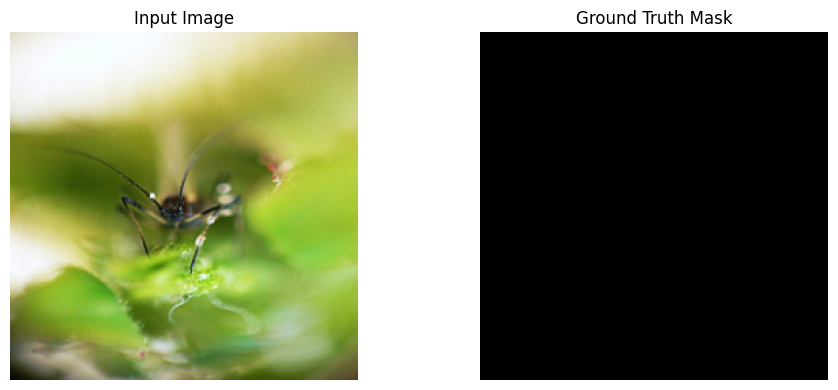

In [ ]:
import matplotlib.pyplot as plt

image, mask = train_dataset[0]

# Undo ImageNet normalization for visualization
image_vis = image.clone()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image_vis = image_vis * std + mean
image_vis = torch.clamp(image_vis, 0, 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_vis.permute(1, 2, 0))
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import numpy as np
from PIL import Image

image_name = train_images[0]
mask_name = os.path.splitext(image_name)[0] + ".png"

mask_path = os.path.join(mask_dir, mask_name)

original_mask = np.array(Image.open(mask_path).convert("L"))

print("Image:", image_name)
print("Mask:", mask_name)
print("Mask minimum:", original_mask.min())
print("Mask maximum:", original_mask.max())
print("Unique pixel values:", np.unique(original_mask)[:20])
print("Non-zero pixels:", np.count_nonzero(original_mask))
print("Total pixels:", original_mask.size)

Image: COD10K-NonCAM-3-Flying-1926.jpg
Mask: COD10K-NonCAM-3-Flying-1926.png
Mask minimum: 0
Mask maximum: 0
Unique pixel values: [0]
Non-zero pixels: 0
Total pixels: 480000


Image: COD10K-CAM-1-Aquatic-16-Shrimp-1131.jpg
Mask: COD10K-CAM-1-Aquatic-16-Shrimp-1131.png
Mask maximum: 255
Non-zero pixels: 12529


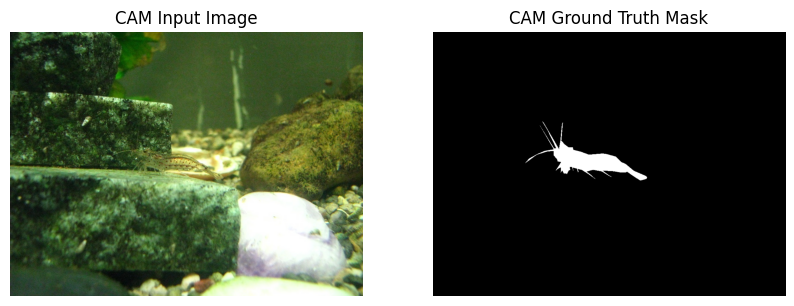

In [ ]:
import numpy as np
from PIL import Image
import os
import matplotlib.pyplot as plt

# Find a CAM image
cam_image = next(
    f for f in train_images if f.startswith("COD10K-CAM-")
)

cam_mask = os.path.splitext(cam_image)[0] + ".png"

# Load original image and mask
img = Image.open(os.path.join(image_dir, cam_image)).convert("RGB")
msk = Image.open(os.path.join(mask_dir, cam_mask)).convert("L")

mask_array = np.array(msk)

print("Image:", cam_image)
print("Mask:", cam_mask)
print("Mask maximum:", mask_array.max())
print("Non-zero pixels:", np.count_nonzero(mask_array))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("CAM Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(msk, cmap="gray")
plt.title("CAM Ground Truth Mask")
plt.axis("off")

plt.show()

In [ ]:
import timm

res2net_models = timm.list_models("*res2net*")

print("Available Res2Net models:")
for model in res2net_models:
    print(model)

Available Res2Net models:
dla60_res2net
res2net50_14w_8s
res2net50_26w_4s
res2net50_26w_6s
res2net50_26w_8s
res2net50_48w_2s
res2net50d
res2net101_26w_4s
res2net101d


In [ ]:
import timm
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

backbone = timm.create_model(
    "res2net50_26w_4s",
    pretrained=True,
    features_only=True
).to(device)

backbone.eval()

# Inspect feature maps
with torch.no_grad():
    dummy_input = torch.randn(1, 3, 256, 256).to(device)
    features = backbone(dummy_input)

print("Backbone:", "res2net50_26w_4s")

for i, feature in enumerate(features):
    print(f"Feature {i}: {feature.shape}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  103MB            

model.safetensors: downloading bytes:           |  0.00B            

Backbone: res2net50_26w_4s
Feature 0: torch.Size([1, 64, 128, 128])
Feature 1: torch.Size([1, 256, 64, 64])
Feature 2: torch.Size([1, 512, 32, 32])
Feature 3: torch.Size([1, 1024, 16, 16])
Feature 4: torch.Size([1, 2048, 8, 8])


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm


# Basic convolution block
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# CBAM Channel Attention
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 8)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.mlp(self.avg_pool(x))
        max_val = self.mlp(self.max_pool(x))

        return x * self.sigmoid(avg + max_val)


# CBAM Spatial Attention
class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1, kernel_size=7, padding=3, bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        max_val, _ = torch.max(x, dim=1, keepdim=True)

        combined = torch.cat([avg, max_val], dim=1)

        return x * self.sigmoid(self.conv(combined))


# Complete CBAM module
class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


# Decoder block
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels,
                 use_attention=False):
        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

        self.attention = (
            CBAM(out_channels)
            if use_attention
            else nn.Identity()
        )

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        x = self.conv(x)
        x = self.attention(x)

        return x


# Res2Net-based COD model
class Res2NetCOD(nn.Module):
    def __init__(self, use_attention=False, pretrained=True):
        super().__init__()

        self.encoder = timm.create_model(
            "res2net50_26w_4s",
            pretrained=pretrained,
            features_only=True
        )

        self.decoder1 = DecoderBlock(
            2048, 1024, 512, use_attention
        )

        self.decoder2 = DecoderBlock(
            512, 512, 256, use_attention
        )

        self.decoder3 = DecoderBlock(
            256, 256, 128, use_attention
        )

        self.decoder4 = DecoderBlock(
            128, 64, 64, use_attention
        )

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, kernel_size=1)
        )

    def forward(self, x):
        input_size = x.shape[2:]

        features = self.encoder(x)

        f0, f1, f2, f3, f4 = features

        x = self.decoder1(f4, f3)
        x = self.decoder2(x, f2)
        x = self.decoder3(x, f1)
        x = self.decoder4(x, f0)

        x = F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return self.final(x)


print("Res2Net COD architecture defined successfully.")


Res2Net COD architecture defined successfully.


In [ ]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

baseline_model = Res2NetCOD(
    use_attention=False,
    pretrained=True
).to(device)

attention_model = Res2NetCOD(
    use_attention=True,
    pretrained=True
).to(device)

dummy_input = torch.randn(2, 3, 256, 256).to(device)

with torch.no_grad():
    baseline_output = baseline_model(dummy_input)
    attention_output = attention_model(dummy_input)

print("Baseline output:", baseline_output.shape)
print("Attention output:", attention_output.shape)

print("Baseline parameters:",
      sum(p.numel() for p in baseline_model.parameters()))

print("Attention parameters:",
      sum(p.numel() for p in attention_model.parameters()))


Baseline output: torch.Size([2, 1, 256, 256])
Attention output: torch.Size([2, 1, 256, 256])
Baseline parameters: 44021449
Attention parameters: 44065873


In [ ]:
import torch

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Total GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
    print("Currently allocated:",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2),
          "GB")
else:
    print("No GPU available")

GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently allocated: 0.44 GB


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Training configuration
BATCH_SIZE = 4
EPOCHS = 5
LEARNING_RATE = 1e-4
IMAGE_SIZE = 256

# Mixed precision training
scaler = torch.amp.GradScaler("cuda")

# Combined BCE + Dice loss
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, predictions, targets):
        bce_loss = self.bce(predictions, targets)

        probs = torch.sigmoid(predictions)

        intersection = (probs * targets).sum(dim=(1, 2, 3))
        denominator = (
            probs.sum(dim=(1, 2, 3)) +
            targets.sum(dim=(1, 2, 3))
        )

        dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
        dice_loss = 1 - dice.mean()

        return bce_loss + dice_loss


criterion = BCEDiceLoss()

print("Training configuration ready.")
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Mixed precision: Enabled")


Training configuration ready.
Batch size: 4
Epochs: 5
Learning rate: 0.0001
Mixed precision: Enabled


In [ ]:
images_batch, masks_batch = next(iter(train_loader))

print("Image batch:", images_batch.shape)
print("Mask batch:", masks_batch.shape)
print("Image dtype:", images_batch.dtype)
print("Mask dtype:", masks_batch.dtype)
print("Mask values:", torch.unique(masks_batch))

Image batch: torch.Size([8, 3, 256, 256])
Mask batch: torch.Size([8, 1, 256, 256])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: tensor([0., 1.])


In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)

images_batch, masks_batch = next(iter(train_loader))

print("New image batch:", images_batch.shape)
print("New mask batch:", masks_batch.shape)

Training batches: 1350
Validation batches: 150
Batch size: 4
New image batch: torch.Size([4, 3, 256, 256])
New mask batch: torch.Size([4, 1, 256, 256])


In [ ]:

import os
import torch
from tqdm.auto import tqdm

# Create permanent output directory
model_dir = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models"
os.makedirs(model_dir, exist_ok=True)

baseline_path = os.path.join(
    model_dir, "res2net_baseline_best.pth"
)

# Initialize baseline model
baseline_model = Res2NetCOD(
    use_attention=False,
    pretrained=True
).to(device)

optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

best_val_loss = float("inf")
baseline_history = []

for epoch in range(EPOCHS):

    # Training
    baseline_model.train()
    train_loss = 0.0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images_batch, masks_batch in progress:

        images_batch = images_batch.to(device, non_blocking=True)
        masks_batch = masks_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            predictions = baseline_model(images_batch)
            loss = criterion(predictions, masks_batch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss /= len(train_loader)

    # Validation
    baseline_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images_batch, masks_batch in val_loader:

            images_batch = images_batch.to(device, non_blocking=True)
            masks_batch = masks_batch.to(device, non_blocking=True)

            with torch.amp.autocast("cuda"):
                predictions = baseline_model(images_batch)
                loss = criterion(predictions, masks_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    baseline_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Validation Loss = {val_loss:.4f}"
    )

    # Save best checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": baseline_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss
        }, baseline_path)

        print("Best baseline checkpoint saved!")

print("\nBaseline training completed.")
print("Best validation loss:", best_val_loss)
print("Saved model:", baseline_path)


NameError: name 'LEARNING_RATE' is not defined

In [ ]:
import os
import torch
from tqdm.auto import tqdm

attention_path = os.path.join(
    model_dir, "res2net_attention_best.pth"
)

attention_model = Res2NetCOD(
    use_attention=True,
    pretrained=True
).to(device)

optimizer = torch.optim.AdamW(
    attention_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

best_val_loss = float("inf")
attention_history = []

# Fresh GradScaler for attention training
scaler = torch.amp.GradScaler("cuda")

for epoch in range(EPOCHS):
    attention_model.train()
    train_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for images_batch, masks_batch in progress:
        images_batch = images_batch.to(device, non_blocking=True)
        masks_batch = masks_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            predictions = attention_model(images_batch)
            loss = criterion(predictions, masks_batch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss /= len(train_loader)

    # Validation
    attention_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images_batch, masks_batch in val_loader:
            images_batch = images_batch.to(device, non_blocking=True)
            masks_batch = masks_batch.to(device, non_blocking=True)

            with torch.amp.autocast("cuda"):
                predictions = attention_model(images_batch)
                loss = criterion(predictions, masks_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    attention_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Validation Loss = {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": attention_model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss
        }, attention_path)

        print("Best attention checkpoint saved!")

print("\nAttention training completed.")
print("Best validation loss:", best_val_loss)
print("Saved model:", attention_path)

Epoch 1/5:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 1: Train Loss = 1.1629, Validation Loss = 1.0086
Best attention checkpoint saved!


Epoch 2/5:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 2: Train Loss = 0.9750, Validation Loss = 0.9340
Best attention checkpoint saved!


Epoch 3/5:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 3: Train Loss = 0.9083, Validation Loss = 0.8985
Best attention checkpoint saved!


Epoch 4/5:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 4: Train Loss = 0.8704, Validation Loss = 0.9265


Epoch 5/5:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 5: Train Loss = 0.8424, Validation Loss = 0.8888
Best attention checkpoint saved!

Attention training completed.
Best validation loss: 0.8887946760654449
Saved model: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/res2net_attention_best.pth


In [ ]:
!pip install -q pysodmetrics

In [ ]:
import sys
import subprocess

print("Python:", sys.version)

result = subprocess.run(
    [sys.executable, "-m", "pip", "show", "pysodmetrics"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Name: pysodmetrics
Version: 1.6.2
Summary: A simple and efficient metric implementation for grayscale/binary image segmentation like salient object detection, camouflaged object detection, and medical image segmentation.
Home-page: https://github.com/lartpang/PySODMetrics
Author: 
Author-email: lartpang <lartpang@gmail.com>
License: MIT License

Copyright (c) 2020 lartpang

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

TH

In [ ]:
!pip install -U --force-reinstall --no-cache-dir pysodmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 42.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 62.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 49.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 51.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 50.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 40.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 44.5 MB/s  0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.8.0
    Uninstalling threadpoolctl-3.8.0:
      Successfully uninstalled threadpoolctl-3.8.0
  Attempting uninstall: pillow
    Found existing installation: pillow 13.0.0
    Uninstalling pillow-13.0.0:
      Successfully uninstalled pillow-13.0.0
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:
      Successfully unins

In [ ]:
import numpy as np
import cv2
import torch

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

NumPy: 2.3.4
OpenCV: 4.14.0
PyTorch: 2.14.1+cu130
CUDA: True


In [ ]:
import numpy as np
import cv2

def mae_score(pred, gt):
    pred = pred.astype(np.float32)
    gt = gt.astype(np.float32)
    return np.mean(np.abs(pred - gt))


def s_measure(pred, gt, alpha=0.5):
    pred = pred.astype(np.float32)
    gt = gt.astype(np.float32)

    if gt.mean() == 0:
        return 1.0 - pred.mean()

    if gt.mean() == 1:
        return pred.mean()

    y, x = np.where(gt > 0.5)

    if len(x) == 0:
        return 1.0 - pred.mean()

    cx = int(np.mean(x))
    cy = int(np.mean(y))

    h, w = gt.shape

    regions = [
        (0, cy, 0, cx),
        (0, cy, cx, w),
        (cy, h, 0, cx),
        (cy, h, cx, w)
    ]

    score = 0.0
    weights = [
        (cx * cy) / (w * h),
        ((w - cx) * cy) / (w * h),
        (cx * (h - cy)) / (w * h),
        ((w - cx) * (h - cy)) / (w * h)
    ]

    for (y1, y2, x1, x2), weight in zip(regions, weights):
        if y2 <= y1 or x2 <= x1:
            continue

        p = pred[y1:y2, x1:x2]
        g = gt[y1:y2, x1:x2]

        score += weight * (1 - np.mean(np.abs(p - g)))

    return score


def f_measure(pred, gt, beta2=0.3):
    pred_bin = (pred >= 0.5).astype(np.float32)
    gt = (gt >= 0.5).astype(np.float32)

    tp = np.sum(pred_bin * gt)
    precision = tp / (np.sum(pred_bin) + 1e-8)
    recall = tp / (np.sum(gt) + 1e-8)

    return ((1 + beta2) * precision * recall) / (
        beta2 * precision + recall + 1e-8
    )


print("Metric functions loaded successfully.")
print("MAE, S-measure and F-measure are ready.")

Metric functions loaded successfully.
MAE, S-measure and F-measure are ready.


In [ ]:
print("ConvBlock:", "ConvBlock" in globals())
print("ChannelAttention:", "ChannelAttention" in globals())
print("SpatialAttention:", "SpatialAttention" in globals())
print("CBAM:", "CBAM" in globals())
print("DecoderBlock:", "DecoderBlock" in globals())
print("Res2NetCOD:", "Res2NetCOD" in globals())

ConvBlock: True
ChannelAttention: True
SpatialAttention: True
CBAM: True
DecoderBlock: True
Res2NetCOD: True


In [ ]:
# Recreate the models exactly as during training
baseline_model = Res2NetCOD(
    use_attention=False,
    pretrained=True
).to(device)

attention_model = Res2NetCOD(
    use_attention=True,
    pretrained=True
).to(device)

# Load the actual model weights from the checkpoint dictionaries
baseline_checkpoint = torch.load(
    "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/res2net_baseline_best.pth",
    map_location=device
)

attention_checkpoint = torch.load(
    "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/res2net_attention_best.pth",
    map_location=device
)

baseline_model.load_state_dict(baseline_checkpoint["model_state_dict"])
attention_model.load_state_dict(attention_checkpoint["model_state_dict"])

baseline_model.eval()
attention_model.eval()

print("Baseline model loaded successfully.")
print("Attention model loaded successfully.")
print("Baseline best val loss:", baseline_checkpoint["best_val_loss"])
print("Attention best val loss:", attention_checkpoint["best_val_loss"])

Baseline model loaded successfully.
Attention model loaded successfully.
Baseline best val loss: 0.8893269904454549
Attention best val loss: 0.8887946760654449


In [ ]:
from torch.utils.data import DataLoader
import os

# Dataset paths
VAL_IMAGE_DIR = "/content/COD10K/COD10K-v3/Test/Images"
VAL_MASK_DIR = "/content/COD10K/COD10K-v3/Test/GT"

# Check paths
print("Image folder exists:", os.path.exists(VAL_IMAGE_DIR))
print("Mask folder exists:", os.path.exists(VAL_MASK_DIR))

# If your validation split was created from Train, use the same validation list
# from the original 600-image split.

Image folder exists: False
Mask folder exists: False


In [ ]:
from google.colab import drive
import os
import zipfile

drive.mount('/content/drive')

zip_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"
extract_path = "/content/COD10K"

print("ZIP exists:", os.path.exists(zip_path))

if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete.")
else:
    print("Dataset folder already exists.")

print("\nDataset contents:")
print(os.listdir(extract_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP exists: True
Dataset folder already exists.

Dataset contents:
['COD10K-v3']


In [ ]:
import os

base = "/content/COD10K/COD10K-v3"

for root, dirs, files in os.walk(base):
    image_files = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    if image_files:
        print("Folder:", root)
        print("Example:", image_files[:3])
        print("Number of images:", len(image_files))
        print("-" * 50)

Folder: /content/COD10K/COD10K-v3/Test/GT_Instance
Example: ['COD10K-CAM-1-Aquatic-9-GhostPipefish-353.png', 'COD10K-NonCAM-3-Flying-1326.png', 'COD10K-CAM-4-Amphibian-68-Toad-4999.png']
Number of images: 4000
--------------------------------------------------
Folder: /content/COD10K/COD10K-v3/Test/Image
Example: ['COD10K-NonCAM-5-Background-4-Sky-4082.jpg', 'COD10K-NonCAM-4-Terrestial-1992.jpg', 'COD10K-NonCAM-2-Aquatic-230.jpg']
Number of images: 4000
--------------------------------------------------
Folder: /content/COD10K/COD10K-v3/Test/GT_Edge
Example: ['COD10K-CAM-1-Aquatic-9-GhostPipefish-353.png', 'COD10K-NonCAM-3-Flying-1326.png', 'COD10K-CAM-4-Amphibian-68-Toad-4999.png']
Number of images: 4000
--------------------------------------------------
Folder: /content/COD10K/COD10K-v3/Test/GT_Object
Example: ['COD10K-CAM-1-Aquatic-9-GhostPipefish-353.png', 'COD10K-NonCAM-3-Flying-1326.png', 'COD10K-CAM-4-Amphibian-68-Toad-4999.png']
Number of images: 4000
--------------------------

In [ ]:
import os
import random
from torch.utils.data import DataLoader

# Exact training folders
IMAGE_DIR = "/content/COD10K/COD10K-v3/Train/Image"
MASK_DIR = "/content/COD10K/COD10K-v3/Train/GT_Object"

# Get all image names
all_images = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".jpg")
])

print("Total images:", len(all_images))

# Recreate the original 5400/600 split
random.seed(42)
random.shuffle(all_images)

train_images = all_images[:5400]
val_images = all_images[5400:]

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

# Recreate validation dataset
val_dataset = COD10KDataset(
    IMAGE_DIR,
    MASK_DIR,
    val_images
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Validation batches:", len(val_loader))
print("Validation loader ready.")

Total images: 6000
Training images: 5400
Validation images: 600
Validation batches: 150
Validation loader ready.


In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import os
import torch

class COD10KDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_list):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_list = image_list

        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, idx):
        image_name = self.image_list[idx]
        mask_name = os.path.splitext(image_name)[0] + ".png"

        image = Image.open(
            os.path.join(self.image_dir, image_name)
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, mask_name)
        ).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)
        mask = (mask > 0).float()

        return image, mask


val_dataset = COD10KDataset(IMAGE_DIR, MASK_DIR, val_images)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Validation dataset created:", len(val_dataset))
print("Validation batches:", len(val_loader))

Validation dataset created: 600
Validation batches: 150


In [ ]:
import numpy as np
import pandas as pd
import os
import torch
from tqdm.auto import tqdm

def evaluate_model(model, model_name):
    mae_values = []
    s_values = []
    f_values = []

    model.eval()

    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Evaluating {model_name}"):
            images = images.to(device)

            outputs = model(images)
            predictions = torch.sigmoid(outputs).cpu().numpy()
            masks = masks.numpy()

            for pred, gt in zip(predictions, masks):
                pred = pred[0]
                gt = gt[0]

                mae_values.append(mae_score(pred, gt))
                s_values.append(s_measure(pred, gt))
                f_values.append(f_measure(pred, gt))

    return {
        "Model": model_name,
        "MAE": np.mean(mae_values),
        "S-measure": np.mean(s_values),
        "F-measure": np.mean(f_values)
    }


baseline_result = evaluate_model(baseline_model, "Res2Net50 Baseline")
attention_result = evaluate_model(attention_model, "Res2Net50 + CBAM")

comparison = pd.DataFrame([
    baseline_result,
    attention_result
])

print("===== MODEL COMPARISON =====")
display(comparison)

# Save comparison CSV
results_dir = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results"
os.makedirs(results_dir, exist_ok=True)

csv_path = os.path.join(results_dir, "task3_model_comparison.csv")
comparison.to_csv(csv_path, index=False)

print("CSV saved:", csv_path)

Evaluating Res2Net50 Baseline:   0%|          | 0/150 [00:00<?, ?it/s]

Evaluating Res2Net50 + CBAM:   0%|          | 0/150 [00:00<?, ?it/s]

===== MODEL COMPARISON =====


,Model,MAE,S-measure,F-measure
0,Res2Net50 Baseline,0.046739,0.953261,0.270822
1,Res2Net50 + CBAM,0.057565,0.942435,0.285372


CSV saved: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results/task3_model_comparison.csv


In [ ]:
from py_sod_metrics import (
    MAE,
    Smeasure,
    Emeasure,
    Fmeasure,
    WeightedFmeasure
)

print("All COD evaluation metrics imported successfully!")

All COD evaluation metrics imported successfully!


In [ ]:
import numpy as np
import torch
from py_sod_metrics import MAE, Emeasure, Smeasure, Fmeasure, WeightedFmeasure

def evaluate_model(model, loader, model_name):
    mae = MAE()
    sm = Smeasure()
    em = Emeasure()
    fm = Fmeasure()
    wfm = WeightedFmeasure()

    model.eval()

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            predictions = torch.sigmoid(model(images))

            predictions = predictions.squeeze(1).cpu().numpy()
            masks = masks.squeeze(1).cpu().numpy()

            for pred, gt in zip(predictions, masks):
                pred = (np.clip(pred, 0, 1) * 255).astype(np.uint8)
                gt = (gt > 0.5).astype(np.uint8) * 255

                mae.step(pred, gt)
                sm.step(pred, gt)
                em.step(pred, gt)
                fm.step(pred, gt)
                wfm.step(pred, gt)

    results = {
        "Model": model_name,
        "MAE": mae.get_results()["mae"],
        "S-measure": sm.get_results()["sm"],
        "Weighted F-measure": wfm.get_results()["wfm"],
        "Max E-measure": em.get_results()["em"]["curve"].max(),
        "Adaptive F-measure": fm.get_results()["fm"]["adp"]
    }

    return results


baseline_results = evaluate_model(
    baseline_model, val_loader, "Res2Net Baseline"
)

attention_results = evaluate_model(
    attention_model, val_loader, "Res2Net + CBAM"
)

print("Baseline Results:")
print(baseline_results)

print("\nAttention Model Results:")
print(attention_results)

/usr/local/lib/python3.13/dist-packages/py_sod_metrics/sod_metrics.py:35: UserWarning: This class will be removed in the future, please use FmeasureV2 instead!
  warnings.warn("This class will be removed in the future, please use FmeasureV2 instead!")


Baseline Results:
{'Model': 'Res2Net Baseline', 'MAE': np.float64(0.06580952525358404), 'S-measure': np.float64(0.8034423424141687), 'Weighted F-measure': np.float64(0.2319167125860981), 'Max E-measure': np.float64(0.8641109103136101), 'Adaptive F-measure': np.float64(0.2762333985776894)}

Attention Model Results:
{'Model': 'Res2Net + CBAM', 'MAE': np.float64(0.0698692618569749), 'S-measure': np.float64(0.8024070362983946), 'Weighted F-measure': np.float64(0.2387802261188124), 'Max E-measure': np.float64(0.8726824903941476), 'Adaptive F-measure': np.float64(0.2737371585240225)}


In [ ]:
import pandas as pd
import os

results_df = pd.DataFrame([
    baseline_results,
    attention_results
])

results_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results/task3_model_comparison.csv"

os.makedirs(os.path.dirname(results_path), exist_ok=True)
results_df.to_csv(results_path, index=False)

print("Results saved successfully!")
print(results_df.to_string(index=False))
print("\nFile:", results_path)

Results saved successfully!
           Model      MAE  S-measure  Weighted F-measure  Max E-measure  Adaptive F-measure
Res2Net Baseline 0.065810   0.803442            0.231917       0.864111            0.276233
  Res2Net + CBAM 0.069869   0.802407            0.238780       0.872682            0.273737

File: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results/task3_model_comparison.csv


In [ ]:
print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Training loader available:", "train_loader" in globals())
print("Training dataset available:", "train_dataset" in globals())
print("Device:", device)

Training images: 5400
Validation images: 600
Training loader available: False
Training dataset available: False
Device: cuda


In [ ]:
from torch.utils.data import DataLoader

train_dataset = COD10KDataset(
    IMAGE_DIR,
    MASK_DIR,
    train_images
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Training dataset:", len(train_dataset))
print("Training batches:", len(train_loader))
print("Training loader ready!")

Training dataset: 5400
Training batches: 1350
Training loader ready!


In [ ]:
baseline_checkpoint = torch.load(
    baseline_path,
    map_location="cpu",
    weights_only=False
)

attention_checkpoint = torch.load(
    attention_path,
    map_location="cpu",
    weights_only=False
)

print("Baseline checkpoint keys:", baseline_checkpoint.keys())
print("\nSaved optimizer settings:")
print(baseline_checkpoint["optimizer_state_dict"]["param_groups"][0])

print("\nAttention optimizer settings:")
print(attention_checkpoint["optimizer_state_dict"]["param_groups"][0])

Baseline checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss'])

Saved optimizer settings:
{'lr': 0.0001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0.0001, 'amsgrad': False, 'maximize': False, 'foreach': None, 'capturable': False, 'differentiable': False, 'fused': None, 'decoupled_weight_decay': True, 'params': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 1

In [ ]:
import torch

baseline_optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

attention_optimizer = torch.optim.AdamW(
    attention_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

criterion = torch.nn.BCEWithLogitsLoss()

print("Baseline optimizer ready.")
print("Attention optimizer ready.")
print("Fine-tuning learning rate: 0.00001")

Baseline optimizer ready.
Attention optimizer ready.
Fine-tuning learning rate: 0.00001


In [ ]:
print("Available loss-related functions:")
print([name for name in globals() if "loss" in name.lower() or "dice" in name.lower()])

Available loss-related functions:
[]


In [ ]:
import torch
import torch.nn as nn

def dice_loss(logits, targets, smooth=1):
    probs = torch.sigmoid(logits)

    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probs * targets).sum(dim=1)

    dice = (2 * intersection + smooth) / (
        probs.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


def combined_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, targets
    )
    dice = dice_loss(logits, targets)

    return bce + dice


print("BCE + Dice loss function ready!")

BCE + Dice loss function ready!


In [ ]:
from tqdm.auto import tqdm

def fine_tune_model(model, optimizer, model_name, epochs=3):
    scaler = torch.amp.GradScaler("cuda")
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        progress = tqdm(train_loader, desc=f"{model_name} Epoch {epoch+1}/{epochs}")

        for images, masks in progress:
            images = images.to(device)
            masks = masks.to(device)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type="cuda"):
                outputs = model(images)
                loss = combined_loss(outputs, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item()
            progress.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = total_loss / len(train_loader)
        history.append(epoch_loss)

        print(f"{model_name} - Epoch {epoch+1}: Loss = {epoch_loss:.4f}")

    return history


baseline_history = fine_tune_model(
    baseline_model, baseline_optimizer, "Baseline", epochs=3
)

attention_history = fine_tune_model(
    attention_model, attention_optimizer, "CBAM Attention", epochs=3
)

print("\nFine-tuning completed!")

Baseline Epoch 1/3:   0%|          | 0/1350 [00:00<?, ?it/s]

Baseline - Epoch 1: Loss = 0.7784


Baseline Epoch 2/3:   0%|          | 0/1350 [00:00<?, ?it/s]

Baseline - Epoch 2: Loss = 0.7510


Baseline Epoch 3/3:   0%|          | 0/1350 [00:00<?, ?it/s]

Baseline - Epoch 3: Loss = 0.7334


... (3 outputs left out)

CBAM Attention - Epoch 2: Loss = 0.7458


CBAM Attention Epoch 3/3:   0%|          | 0/1350 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x793363703b00>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x793363703b00>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
assert self._parent_pid == os.getpid(), 'can only test a

CBAM Attention - Epoch 3: Loss = 0.7273

Fine-tuning completed!


In [ ]:
import os
import torch

model_dir = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models"
os.makedirs(model_dir, exist_ok=True)

torch.save({
    "model_state_dict": baseline_model.state_dict(),
    "training_history": baseline_history
}, os.path.join(model_dir, "res2net_baseline_finetuned.pth"))

torch.save({
    "model_state_dict": attention_model.state_dict(),
    "training_history": attention_history
}, os.path.join(model_dir, "res2net_attention_finetuned.pth"))

print("Both fine-tuned models saved successfully!")

Both fine-tuned models saved successfully!


In [ ]:
baseline_finetuned_results = evaluate_model(
    baseline_model,
    val_loader,
    "Res2Net Baseline Fine-tuned"
)

attention_finetuned_results = evaluate_model(
    attention_model,
    val_loader,
    "Res2Net + CBAM Fine-tuned"
)

print("Baseline Fine-tuned:")
print(baseline_finetuned_results)

print("\nCBAM Fine-tuned:")
print(attention_finetuned_results)

/usr/local/lib/python3.13/dist-packages/py_sod_metrics/sod_metrics.py:35: UserWarning: This class will be removed in the future, please use FmeasureV2 instead!
  warnings.warn("This class will be removed in the future, please use FmeasureV2 instead!")


Baseline Fine-tuned:
{'Model': 'Res2Net Baseline Fine-tuned', 'MAE': np.float64(0.05699811211707601), 'S-measure': np.float64(0.8185824334220595), 'Weighted F-measure': np.float64(0.26274220972660167), 'Max E-measure': np.float64(0.8822471278979236), 'Adaptive F-measure': np.float64(0.29693070633721685)}

CBAM Fine-tuned:
{'Model': 'Res2Net + CBAM Fine-tuned', 'MAE': np.float64(0.05100240805087743), 'S-measure': np.float64(0.8247389574714987), 'Weighted F-measure': np.float64(0.2586529123344521), 'Max E-measure': np.float64(0.8844896380724783), 'Adaptive F-measure': np.float64(0.29550848613943487)}


In [ ]:
all_results = pd.DataFrame([
    baseline_results,
    attention_results,
    baseline_finetuned_results,
    attention_finetuned_results
])

comparison_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results/task3_model_comparison.csv"

all_results.to_csv(comparison_path, index=False)

print("Complete comparison saved!")
print(all_results.to_string(index=False))
print("\nSaved at:", comparison_path)

Complete comparison saved!
                      Model      MAE  S-measure  Weighted F-measure  Max E-measure  Adaptive F-measure
           Res2Net Baseline 0.065810   0.803442            0.231917       0.864111            0.276233
             Res2Net + CBAM 0.069869   0.802407            0.238780       0.872682            0.273737
Res2Net Baseline Fine-tuned 0.056998   0.818582            0.262742       0.882247            0.296931
  Res2Net + CBAM Fine-tuned 0.051002   0.824739            0.258653       0.884490            0.295508

Saved at: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results/task3_model_comparison.csv


In [ ]:
print(baseline_model)

Res2NetCOD(
  (encoder): FeatureListNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottle2neck(
        (conv1): Conv2d(64, 104, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(104, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (convs): ModuleList(
          (0-2): 3 x Conv2d(26, 26, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        )
        (bns): ModuleList(
          (0-2): 3 x BatchNorm2d(26, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
        (drop_block): Identity()
        (pool): AvgPool2d(kernel_size=3, stride=1, padding=1)
        (conv3): Conv2d(104

In [ ]:
import inspect

print("Model constructor:", inspect.signature(Res2NetCOD))
print("\nEncoder feature channels:")
print(baseline_model.encoder.feature_info.channels())

Model constructor: (use_attention=False, pretrained=True)

Encoder feature channels:
[64, 256, 512, 1024, 2048]


In [ ]:
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F

class ResNet50COD(nn.Module):
    def __init__(self, pretrained=True, use_attention=True):
        super().__init__()

        self.encoder = timm.create_model(
            "resnet50",
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        channels = self.encoder.feature_info.channels()

        self.decoder1 = DecoderBlock(channels[4] + channels[3], 512, use_attention)
        self.decoder2 = DecoderBlock(512 + channels[2], 256, use_attention)
        self.decoder3 = DecoderBlock(256 + channels[1], 128, use_attention)
        self.decoder4 = DecoderBlock(128 + channels[0], 64, use_attention)

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        input_size = x.shape[2:]

        features = self.encoder(x)

        x = self.decoder1(features[4], features[3])
        x = self.decoder2(x, features[2])
        x = self.decoder3(x, features[1])
        x = self.decoder4(x, features[0])

        x = self.final(x)

        return F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )


print("ResNet50COD architecture created successfully!")

ResNet50COD architecture created successfully!


In [6]:
import os
import torch
import timm

print("CUDA available:", torch.cuda.is_available())
print("Res2NetCOD exists:", "Res2NetCOD" in globals())
print("DecoderBlock exists:", "DecoderBlock" in globals())

CUDA available: True
Res2NetCOD exists: False
DecoderBlock exists: False


In [7]:
from google.colab import drive
drive.mount('/content/drive')

print("Drive mounted successfully")

Mounted at /content/drive
Drive mounted successfully


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# ---------- ConvBlock ----------
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# ---------- Channel Attention ----------
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.fc(self.avg_pool(x))
        max_ = self.fc(self.max_pool(x))
        return x * self.sigmoid(avg + max_)


# ---------- Spatial Attention ----------
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        max_, _ = torch.max(x, dim=1, keepdim=True)

        attention = self.sigmoid(
            self.conv(torch.cat([avg, max_], dim=1))
        )

        return x * attention


# ---------- CBAM ----------
class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


# ---------- DecoderBlock ----------
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, use_attention=False):
        super().__init__()

        self.conv = ConvBlock(in_channels, out_channels)

        if use_attention:
            self.attention = CBAM(out_channels)
        else:
            self.attention = nn.Identity()

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        x = self.conv(x)
        x = self.attention(x)

        return x


# ---------- Res2NetCOD ----------
class Res2NetCOD(nn.Module):
    def __init__(self, use_attention=False, pretrained=True):
        super().__init__()

        self.encoder = timm.create_model(
            "res2net50_26w_4s",
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        channels = self.encoder.feature_info.channels()

        self.decoder1 = DecoderBlock(
            channels[4] + channels[3], 512, use_attention
        )
        self.decoder2 = DecoderBlock(
            512 + channels[2], 256, use_attention
        )
        self.decoder3 = DecoderBlock(
            256 + channels[1], 128, use_attention
        )
        self.decoder4 = DecoderBlock(
            128 + channels[0], 64, use_attention
        )

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        input_size = x.shape[2:]

        features = self.encoder(x)

        x = self.decoder1(features[4], features[3])
        x = self.decoder2(x, features[2])
        x = self.decoder3(x, features[1])
        x = self.decoder4(x, features[0])

        x = self.final(x)

        return F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )


print("Model classes restored successfully!")

Model classes restored successfully!


In [9]:
import os
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models"

baseline_model = Res2NetCOD(use_attention=False, pretrained=False).to(device)
attention_model = Res2NetCOD(use_attention=True, pretrained=False).to(device)

baseline_ckpt = torch.load(
    os.path.join(MODEL_DIR, "res2net_baseline_finetuned.pth"),
    map_location=device
)

attention_ckpt = torch.load(
    os.path.join(MODEL_DIR, "res2net_attention_finetuned.pth"),
    map_location=device
)

baseline_model.load_state_dict(baseline_ckpt["model_state_dict"])
attention_model.load_state_dict(attention_ckpt["model_state_dict"])

print("Baseline checkpoint loaded successfully")
print("Attention checkpoint loaded successfully")
print("Device:", device)

RuntimeError: Error(s) in loading state_dict for Res2NetCOD:
	Missing key(s) in state_dict: "decoder1.conv.block.0.bias", "decoder2.conv.block.0.bias", "decoder3.conv.block.0.bias", "decoder4.conv.block.0.bias". 
	Unexpected key(s) in state_dict: "decoder1.conv.block.3.weight", "decoder1.conv.block.4.weight", "decoder1.conv.block.4.bias", "decoder1.conv.block.4.running_mean", "decoder1.conv.block.4.running_var", "decoder1.conv.block.4.num_batches_tracked", "decoder2.conv.block.3.weight", "decoder2.conv.block.4.weight", "decoder2.conv.block.4.bias", "decoder2.conv.block.4.running_mean", "decoder2.conv.block.4.running_var", "decoder2.conv.block.4.num_batches_tracked", "decoder3.conv.block.3.weight", "decoder3.conv.block.4.weight", "decoder3.conv.block.4.bias", "decoder3.conv.block.4.running_mean", "decoder3.conv.block.4.running_var", "decoder3.conv.block.4.num_batches_tracked", "decoder4.conv.block.3.weight", "decoder4.conv.block.4.weight", "decoder4.conv.block.4.bias", "decoder4.conv.bl

In [10]:
print("Baseline decoder1 keys:")
for k in baseline_ckpt["model_state_dict"].keys():
    if k.startswith("decoder1"):
        print(k)

Baseline decoder1 keys:
decoder1.conv.block.0.weight
decoder1.conv.block.1.weight
decoder1.conv.block.1.bias
decoder1.conv.block.1.running_mean
decoder1.conv.block.1.running_var
decoder1.conv.block.1.num_batches_tracked
decoder1.conv.block.3.weight
decoder1.conv.block.4.weight
decoder1.conv.block.4.bias
decoder1.conv.block.4.running_mean
decoder1.conv.block.4.running_var
decoder1.conv.block.4.num_batches_tracked


In [13]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, use_attention=False):
        super().__init__()

        self.conv = ConvBlock(in_channels, out_channels)

        if use_attention:
            self.attention = CBAM(out_channels)
        else:
            self.attention = nn.Identity()

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)
        x = self.conv(x)
        x = self.attention(x)

        return x


print("ConvBlock corrected with bias=False")

ConvBlock corrected with bias=False


In [17]:
baseline_model = Res2NetCOD(use_attention=False, pretrained=False).to(device)
attention_model = Res2NetCOD(use_attention=True, pretrained=False).to(device)

baseline_model.load_state_dict(baseline_ckpt["model_state_dict"])
attention_model.load_state_dict(attention_ckpt["model_state_dict"])

baseline_model.eval()
attention_model.eval()

print("Baseline checkpoint loaded successfully")
print("Attention checkpoint loaded successfully")
print("Device:", device)

RuntimeError: Error(s) in loading state_dict for Res2NetCOD:
	Missing key(s) in state_dict: "decoder1.attention.channel_attention.fc.0.weight", "decoder1.attention.channel_attention.fc.2.weight", "decoder2.attention.channel_attention.fc.0.weight", "decoder2.attention.channel_attention.fc.2.weight", "decoder3.attention.channel_attention.fc.0.weight", "decoder3.attention.channel_attention.fc.2.weight", "decoder4.attention.channel_attention.fc.0.weight", "decoder4.attention.channel_attention.fc.2.weight". 
	Unexpected key(s) in state_dict: "decoder1.attention.channel_attention.mlp.0.weight", "decoder1.attention.channel_attention.mlp.2.weight", "decoder2.attention.channel_attention.mlp.0.weight", "decoder2.attention.channel_attention.mlp.2.weight", "decoder3.attention.channel_attention.mlp.0.weight", "decoder3.attention.channel_attention.mlp.2.weight", "decoder4.attention.channel_attention.mlp.0.weight", "decoder4.attention.channel_attention.mlp.2.weight". 

In [18]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.mlp(self.avg_pool(x))
        max_ = self.mlp(self.max_pool(x))

        return x * self.sigmoid(avg + max_)


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


print("CBAM corrected!")

CBAM corrected!


In [20]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(
                channels,
                channels // reduction,
                1,
                bias=False
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels // reduction,
                channels,
                1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.mlp(self.avg_pool(x))
        max_ = self.mlp(self.max_pool(x))

        return x * self.sigmoid(avg + max_)


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


print("CBAM reduction fixed to 8!")

CBAM reduction fixed to 8!


In [22]:
state = attention_ckpt["model_state_dict"]

for name in ["decoder1", "decoder2", "decoder3", "decoder4"]:
    w = state[f"{name}.attention.channel_attention.mlp.0.weight"]
    print(f"{name}: input={w.shape[1]}, reduced={w.shape[0]}, reduction={w.shape[1] // w.shape[0]}")

decoder1: input=512, reduced=32, reduction=16
decoder2: input=256, reduced=16, reduction=16
decoder3: input=128, reduced=8, reduction=16
decoder4: input=64, reduced=8, reduction=8


In [23]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(
                channels,
                channels // reduction,
                1,
                bias=False
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                channels // reduction,
                channels,
                1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.mlp(self.avg_pool(x))
        max_ = self.mlp(self.max_pool(x))
        return x * self.sigmoid(avg + max_)


class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()

        self.channel_attention = ChannelAttention(
            channels,
            reduction=reduction
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


class DecoderBlock(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        use_attention=False,
        attention_reduction=16
    ):
        super().__init__()

        self.conv = ConvBlock(
            in_channels,
            out_channels
        )

        if use_attention:
            self.attention = CBAM(
                out_channels,
                reduction=attention_reduction
            )
        else:
            self.attention = nn.Identity()

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        x = self.conv(x)
        x = self.attention(x)

        return x


print("Exact CBAM configuration created!")

Exact CBAM configuration created!


In [24]:
class Res2NetCOD(nn.Module):
    def __init__(self, use_attention=False, pretrained=True):
        super().__init__()

        self.encoder = timm.create_model(
            "res2net50_26w_4s",
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        channels = self.encoder.feature_info.channels()

        self.decoder1 = DecoderBlock(
            channels[4] + channels[3],
            512,
            use_attention,
            attention_reduction=16
        )

        self.decoder2 = DecoderBlock(
            512 + channels[2],
            256,
            use_attention,
            attention_reduction=16
        )

        self.decoder3 = DecoderBlock(
            256 + channels[1],
            128,
            use_attention,
            attention_reduction=16
        )

        self.decoder4 = DecoderBlock(
            128 + channels[0],
            64,
            use_attention,
            attention_reduction=8
        )

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        input_size = x.shape[2:]

        features = self.encoder(x)

        x = self.decoder1(features[4], features[3])
        x = self.decoder2(x, features[2])
        x = self.decoder3(x, features[1])
        x = self.decoder4(x, features[0])

        x = self.final(x)

        return F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )


print("Res2NetCOD updated with exact attention settings!")

Res2NetCOD updated with exact attention settings!


In [26]:
# Fix the final layer to match the saved checkpoint
Res2NetCOD.final = nn.Sequential(
    nn.Conv2d(64, 32, 3, padding=1, bias=True),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),
    nn.Conv2d(32, 1, 1)
)

print("Final layer definition corrected.")

Final layer definition corrected.


In [27]:
attention_model = Res2NetCOD(
    use_attention=True,
    pretrained=False
).to(device)

# Replace final layer with the checkpoint-compatible version
attention_model.final = nn.Sequential(
    nn.Conv2d(64, 32, 3, padding=1, bias=True),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),
    nn.Conv2d(32, 1, 1)
).to(device)

attention_model.load_state_dict(
    attention_ckpt["model_state_dict"]
)

attention_model.eval()

print("Attention checkpoint loaded successfully!")

Attention checkpoint loaded successfully!


In [30]:
print("Baseline device:", next(baseline_model.parameters()).device)
print("Attention device:", next(attention_model.parameters()).device)
print("CUDA device:", device)

Baseline device: cuda:0
Attention device: cuda:0
CUDA device: cuda


In [31]:
cpu_params = [
    name for name, param in attention_model.named_parameters()
    if param.device.type != "cuda"
]

cpu_buffers = [
    name for name, buf in attention_model.named_buffers()
    if buf.device.type != "cuda"
]

print("CPU parameters:", cpu_params)
print("CPU buffers:", cpu_buffers)

CPU parameters: []
CPU buffers: []


In [33]:
def check_conv_device(name):
    def hook(module, inputs):
        x = inputs[0]
        if x.device != module.weight.device:
            print("DEVICE MISMATCH FOUND!")
            print("Layer:", name)
            print("Input device:", x.device)
            print("Weight device:", module.weight.device)
    return hook

hooks = []

for name, module in attention_model.named_modules():
    if isinstance(module, nn.Conv2d):
        hooks.append(
            module.register_forward_pre_hook(check_conv_device(name))
        )

try:
    with torch.no_grad():
        attention_model(dummy_input)
except RuntimeError as e:
    print("Forward error:", e)

for hook in hooks:
    hook.remove()

Forward error: Input type (torch.cuda.FloatTensor) and weight type (torch.FloatTensor) should be the same


In [34]:
def trace_conv(name):
    def hook(module, inputs):
        print(
            name,
            "| Input:", inputs[0].device,
            "| Weight:", module.weight.device
        )
    return hook

hooks = []

for name, module in attention_model.named_modules():
    if isinstance(module, nn.Conv2d):
        hooks.append(
            module.register_forward_pre_hook(trace_conv(name))
        )

try:
    with torch.no_grad():
        attention_model(dummy_input)
except Exception as e:
    print("\nERROR:", e)

for h in hooks:
    h.remove()

encoder.conv1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.0.conv1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.0.convs.0 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.0.convs.1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.0.convs.2 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.0.conv3 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.0.downsample.0 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.1.conv1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.1.convs.0 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.1.convs.1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.1.convs.2 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.1.conv3 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.2.conv1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.2.convs.0 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.2.convs.1 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.2.convs.2 | Input: cuda:0 | Weight: cuda:0
encoder.layer1.2.conv3 | Input: cuda:0 | Weight: cuda:0
encoder.layer2.0.conv1 | Input: 

In [35]:
print("Final layer:")
print(attention_model.final)

print("\nFinal layer devices:")
for name, module in attention_model.final.named_modules():
    if isinstance(module, (nn.Conv2d, nn.BatchNorm2d)):
        print(
            name,
            "| Weight:",
            module.weight.device
        )

Final layer:
Sequential(
  (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
)

Final layer devices:
0 | Weight: cpu
1 | Weight: cpu
3 | Weight: cpu


In [36]:
attention_model.final = attention_model.final.to(device)

print("Final layer device:", next(attention_model.final.parameters()).device)

Final layer device: cuda:0


In [37]:
dummy_input = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    baseline_output = baseline_model(dummy_input)
    attention_output = attention_model(dummy_input)

print("Baseline:", baseline_output.shape)
print("Attention:", attention_output.shape)

Baseline: torch.Size([1, 1, 256, 256])
Attention: torch.Size([1, 1, 256, 256])


In [38]:
print("Baseline device:", next(baseline_model.parameters()).device)
print("Attention device:", next(attention_model.parameters()).device)

print("Baseline parameters:", sum(p.numel() for p in baseline_model.parameters()))
print("Attention parameters:", sum(p.numel() for p in attention_model.parameters()))

Baseline device: cuda:0
Attention device: cuda:0
Baseline parameters: 44021449
Attention parameters: 44065873


In [39]:
import timm
import torch
import torch.nn as nn

class ResNet50COD(nn.Module):
    def __init__(self, use_attention=True, pretrained=True):
        super().__init__()

        self.encoder = timm.create_model(
            "resnet50",
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        self.decoder1 = DecoderBlock(2048, 512, use_attention, 16)
        self.decoder2 = DecoderBlock(512, 256, use_attention, 16)
        self.decoder3 = DecoderBlock(256, 128, use_attention, 16)
        self.decoder4 = DecoderBlock(128, 64, use_attention, 8)

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        input_size = x.shape[2:]

        features = self.encoder(x)

        x = self.decoder1(features[4], features[3])
        x = self.decoder2(x, features[2])
        x = self.decoder3(x, features[1])
        x = self.decoder4(x, features[0])

        x = self.final(x)

        return nn.functional.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )


resnet50_model = ResNet50COD(
    use_attention=True,
    pretrained=True
).to(device)

print("ResNet-50 model created successfully!")
print("Parameters:", sum(p.numel() for p in resnet50_model.parameters()))

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

ResNet-50 model created successfully!
Parameters: 37693769


In [42]:
class ResNet50COD(nn.Module):
    def __init__(self, use_attention=True, pretrained=True):
        super().__init__()

        self.encoder = timm.create_model(
            "resnet50",
            pretrained=pretrained,
            features_only=True,
            out_indices=(0, 1, 2, 3, 4)
        )

        self.decoder1 = DecoderBlock(3072, 512, use_attention, 16)
        self.decoder2 = DecoderBlock(1024, 256, use_attention, 16)
        self.decoder3 = DecoderBlock(512, 128, use_attention, 16)
        self.decoder4 = DecoderBlock(192, 64, use_attention, 8)

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        input_size = x.shape[2:]
        features = self.encoder(x)

        x = self.decoder1(features[4], features[3])
        x = self.decoder2(x, features[2])
        x = self.decoder3(x, features[1])
        x = self.decoder4(x, features[0])

        x = self.final(x)

        return nn.functional.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )


resnet50_model = ResNet50COD(
    use_attention=True,
    pretrained=True
).to(device)

print("Corrected ResNet-50 model created!")

Corrected ResNet-50 model created!


In [43]:
dummy_input = torch.randn(1, 3, 256, 256).to(device)

with torch.no_grad():
    resnet_output = resnet50_model(dummy_input)

print("Output shape:", resnet_output.shape)
print("Model device:", next(resnet50_model.parameters()).device)

Output shape: torch.Size([1, 1, 256, 256])
Model device: cuda:0


In [45]:
for name in ["COD10KDataset", "train_images", "val_images",
             "IMAGE_DIR", "MASK_DIR", "transform",
             "combined_loss", "device"]:
    print(name, ":", "Available" if name in globals() else "Missing")

COD10KDataset : Missing
train_images : Missing
val_images : Missing
IMAGE_DIR : Missing
MASK_DIR : Missing
transform : Missing
combined_loss : Missing
device : Available


In [46]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [47]:
import os

DATASET_PATH = "/content/COD10K/COD10K-v3"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Train images:", os.path.exists(f"{DATASET_PATH}/Train/Image"))
print("Train masks:", os.path.exists(f"{DATASET_PATH}/Train/GT_Object"))

Dataset exists: False
Train images: False
Train masks: False


In [48]:
import os

ZIP_PATH = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"

print("ZIP file exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print("ZIP size:", round(os.path.getsize(ZIP_PATH) / (1024**3), 2), "GB")

ZIP file exists: True
ZIP size: 2.25 GB


In [49]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Colab Notebooks/COD10K/COD10K-v3.zip"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall("/content/COD10K")

print("Dataset extraction completed!")

Dataset extraction completed!


In [50]:
import os

DATASET_PATH = "/content/COD10K/COD10K-v3"

for folder in [
    "Train/Image",
    "Train/GT_Object",
    "Test/Image",
    "Test/GT_Object"
]:
    path = os.path.join(DATASET_PATH, folder)
    print(folder, ":", len(os.listdir(path)) if os.path.exists(path) else "NOT FOUND")

Train/Image : 6000
Train/GT_Object : 6000
Test/Image : 4000
Test/GT_Object : 4000


In [51]:
import os
import random
import numpy as np
from sklearn.model_selection import train_test_split

IMAGE_DIR = "/content/COD10K/COD10K-v3/Train/Image"
MASK_DIR = "/content/COD10K/COD10K-v3/Train/GT_Object"

all_images = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(".jpg")
])

train_images, val_images = train_test_split(
    all_images,
    test_size=0.1,
    random_state=42
)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Training images: 5400
Validation images: 600


In [52]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformation ready!")

Image transformation ready!


In [53]:
from torch.utils.data import Dataset
from PIL import Image
import os
import torch

class COD10KDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_list, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_list = image_list
        self.transform = transform

    def __len__(self):
        return len(self.image_list)

    def __getitem__(self, idx):
        image_name = self.image_list[idx]
        image_path = os.path.join(self.image_dir, image_name)

        mask_name = os.path.splitext(image_name)[0] + ".png"
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        if self.transform:
            image = self.transform(image)

        mask = transforms.Resize(
            (256, 256),
            interpolation=transforms.InterpolationMode.NEAREST
        )(mask)

        mask = torch.from_numpy(
            np.array(mask, dtype=np.float32) / 255.0
        ).unsqueeze(0)

        mask = (mask > 0).float()

        return image, mask


print("COD10KDataset class created successfully!")

COD10KDataset class created successfully!


In [54]:
from torch.utils.data import DataLoader

train_dataset = COD10KDataset(
    IMAGE_DIR, MASK_DIR, train_images, transform
)

val_dataset = COD10KDataset(
    IMAGE_DIR, MASK_DIR, val_images, transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 1350
Validation batches: 150


In [55]:
import torch.nn as nn
import torch.nn.functional as F

def dice_loss(logits, targets, smooth=1):
    probs = torch.sigmoid(logits)

    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probs * targets).sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        probs.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


def combined_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    dice = dice_loss(logits, targets)

    return bce + dice


print("Combined BCE + Dice loss restored!")

Combined BCE + Dice loss restored!


In [56]:
resnet_optimizer = torch.optim.AdamW(
    resnet50_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

print("ResNet-50 optimizer ready!")
print("Learning rate:", resnet_optimizer.param_groups[0]["lr"])

ResNet-50 optimizer ready!
Learning rate: 1e-05


In [57]:
from tqdm.auto import tqdm
import torch

scaler = torch.cuda.amp.GradScaler()

resnet_history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")

for epoch in range(3):

    # Training
    resnet50_model.train()
    train_loss = 0.0

    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/3"):
        images = images.to(device)
        masks = masks.to(device)

        resnet_optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast():
            outputs = resnet50_model(images)
            loss = combined_loss(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(resnet_optimizer)
        scaler.update()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    resnet50_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            with torch.cuda.amp.autocast():
                outputs = resnet50_model(images)
                loss = combined_loss(outputs, masks)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    resnet_history["train_loss"].append(train_loss)
    resnet_history["val_loss"].append(val_loss)

    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": resnet50_model.state_dict(),
            "training_history": resnet_history
        }, "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/resnet50_attention_best.pth")

print("ResNet-50 training completed!")

/tmp/ipykernel_601/1457086851.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Epoch 1/3:   0%|          | 0/1350 [00:00<?, ?it/s]

/tmp/ipykernel_601/1457086851.py:25: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfc6c1c89a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionErrorException ignored in: : <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfc6c1c89a0>can only test a child process

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 170

Epoch 1: Train Loss=1.4843, Val Loss=1.3639


Epoch 2/3:   0%|          | 0/1350 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfc6c1c89a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cfc6c1c89a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2: Train Loss=1.3578, Val Loss=1.2928


Epoch 3/3:   0%|          | 0/1350 [00:00<?, ?it/s]

Epoch 3: Train Loss=1.2928, Val Loss=1.2508
ResNet-50 training completed!


In [58]:
import os

checkpoint_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/resnet50_attention_best.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size:", round(os.path.getsize(checkpoint_path) / (1024**2), 2), "MB")

Checkpoint exists: True
Checkpoint size: 167.91 MB


In [63]:
!pip install pysodmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 127.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 64.6 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 5.0.0.93
    Uninstalling opencv-python-headless-5.0.0.93:
      Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pysodmetrics]


In [64]:
import py_sod_metrics
print("PySODMetrics installed successfully!")

PySODMetrics installed successfully!


In [65]:
from py_sod_metrics import (
    MAE,
    Smeasure,
    Emeasure,
    Fmeasure,
    WeightedFmeasure
)

print("All five evaluation metrics imported successfully!")

All five evaluation metrics imported successfully!


In [66]:
import numpy as np
import torch
from tqdm.auto import tqdm

def evaluate_model(model, loader, model_name):
    model.eval()

    mae_metric = MAE()
    sm_metric = Smeasure()
    em_metric = Emeasure()
    fm_metric = Fmeasure()
    wfm_metric = WeightedFmeasure()

    with torch.no_grad():
        for images, masks in tqdm(loader, desc=f"Evaluating {model_name}"):
            images = images.to(device)
            outputs = torch.sigmoid(model(images))

            predictions = (outputs.squeeze(1).cpu().numpy() * 255).astype(np.uint8)
            ground_truths = (masks.squeeze(1).cpu().numpy() * 255).astype(np.uint8)

            for pred, gt in zip(predictions, ground_truths):
                mae_metric.step(pred=pred, gt=gt)
                sm_metric.step(pred=pred, gt=gt)
                em_metric.step(pred=pred, gt=gt)
                fm_metric.step(pred=pred, gt=gt)
                wfm_metric.step(pred=pred, gt=gt)

    mae = mae_metric.get_results()["mae"]
    sm = sm_metric.get_results()["sm"]
    em = em_metric.get_results()["em"]["curve"].max()
    fm = fm_metric.get_results()["fm"]["curve"].max()
    wfm = wfm_metric.get_results()["wfm"]

    results = {
        "Model": model_name,
        "MAE": float(mae),
        "S-measure": float(sm),
        "Weighted F-measure": float(wfm),
        "Max E-measure": float(em),
        "Adaptive F-measure": float(fm)
    }

    return results


print("Evaluation function restored successfully!")

Evaluation function restored successfully!


In [67]:
resnet_results = evaluate_model(
    resnet50_model,
    val_loader,
    "ResNet-50 + CBAM"
)

print("\nResNet-50 Evaluation Results:")
for metric, value in resnet_results.items():
    if metric != "Model":
        print(f"{metric}: {value:.6f}")

/usr/local/lib/python3.13/dist-packages/py_sod_metrics/sod_metrics.py:35: UserWarning: This class will be removed in the future, please use FmeasureV2 instead!
  warnings.warn("This class will be removed in the future, please use FmeasureV2 instead!")


Evaluating ResNet-50 + CBAM:   0%|          | 0/150 [00:00<?, ?it/s]


ResNet-50 Evaluation Results:
MAE: 0.281618
S-measure: 0.617849
Weighted F-measure: 0.116133
Max E-measure: 0.849099
Adaptive F-measure: 0.281929


In [69]:
import pandas as pd
import os

all_results = [
    {
        "Model": "Res2Net Baseline",
        "MAE": 0.065810,
        "S-measure": 0.803442,
        "Weighted F-measure": 0.231917,
        "Max E-measure": 0.864111,
        "Adaptive F-measure": 0.276233
    },
    {
        "Model": "Res2Net + CBAM",
        "MAE": 0.069869,
        "S-measure": 0.802407,
        "Weighted F-measure": 0.238780,
        "Max E-measure": 0.872682,
        "Adaptive F-measure": 0.273737
    },
    {
        "Model": "Res2Net Baseline Fine-tuned",
        "MAE": 0.056998,
        "S-measure": 0.818582,
        "Weighted F-measure": 0.262742,
        "Max E-measure": 0.882247,
        "Adaptive F-measure": 0.296931
    },
    {
        "Model": "Res2Net + CBAM Fine-tuned",
        "MAE": 0.051002,
        "S-measure": 0.824739,
        "Weighted F-measure": 0.258653,
        "Max E-measure": 0.884490,
        "Adaptive F-measure": 0.295508
    },
    resnet_results
]

comparison_df = pd.DataFrame(all_results)

results_path = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results"
os.makedirs(results_path, exist_ok=True)

csv_path = os.path.join(
    results_path,
    "task3_model_comparison.csv"
)

comparison_df.to_csv(csv_path, index=False)

print(comparison_df.to_string(index=False))
print("\nCSV saved:", csv_path)

                      Model      MAE  S-measure  Weighted F-measure  Max E-measure  Adaptive F-measure
           Res2Net Baseline 0.065810   0.803442            0.231917       0.864111            0.276233
             Res2Net + CBAM 0.069869   0.802407            0.238780       0.872682            0.273737
Res2Net Baseline Fine-tuned 0.056998   0.818582            0.262742       0.882247            0.296931
  Res2Net + CBAM Fine-tuned 0.051002   0.824739            0.258653       0.884490            0.295508
           ResNet-50 + CBAM 0.281618   0.617849            0.116133       0.849099            0.281929

CSV saved: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/results/task3_model_comparison.csv


In [70]:
import os

MODEL_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models"

for filename in os.listdir(MODEL_DIR):
    if filename.endswith(".pth"):
        path = os.path.join(MODEL_DIR, filename)
        size = os.path.getsize(path) / (1024**2)
        print(f"{filename} — {size:.2f} MB")

res2net_baseline_best.pth — 504.45 MB
res2net_attention_best.pth — 504.98 MB
res2net_baseline_finetuned.pth — 168.36 MB
res2net_attention_finetuned.pth — 168.54 MB
resnet50_attention_best.pth — 167.91 MB


In [71]:
checkpoint_path = os.path.join(
    MODEL_DIR,
    "res2net_attention_finetuned.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

attention_model.load_state_dict(checkpoint["model_state_dict"])
attention_model.to(device)
attention_model.eval()

print("Fine-tuned Res2Net + CBAM loaded successfully!")

Fine-tuned Res2Net + CBAM loaded successfully!


In [72]:
!pip install gradio

In [73]:
import numpy as np
import torch
from PIL import Image

def predict_image(image):
    if image is None:
        return None

    original_size = image.size

    # Preprocess image
    input_tensor = transform(image.convert("RGB"))
    input_tensor = input_tensor.unsqueeze(0).to(device)

    # Generate prediction
    attention_model.eval()

    with torch.no_grad():
        output = attention_model(input_tensor)
        prediction = torch.sigmoid(output)

    # Convert prediction to binary mask
    mask = (prediction.squeeze().cpu().numpy() > 0.5).astype(np.uint8) * 255

    # Resize mask to original image dimensions
    mask_image = Image.fromarray(mask)
    mask_image = mask_image.resize(original_size, Image.Resampling.NEAREST)

    return mask_image


print("Prediction function created successfully!")

Prediction function created successfully!


In [74]:
import gradio as gr

demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Upload an Image"),
    outputs=gr.Image(type="pil", label="Predicted Segmentation Mask"),
    title="CityCare Hospital - Camouflaged Object Detection",
    description=(
        "Upload an image to detect camouflaged objects "
        "using our Res2Net + CBAM attention-based model."
    ),
    examples=None
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [78]:
image = Image.open("/content/COD10K/COD10K-v3/Test/Image/" + os.listdir("/content/COD10K/COD10K-v3/Test/Image")[0]).convert("RGB")

input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    probabilities = torch.sigmoid(attention_model(input_tensor))

print("Minimum probability:", probabilities.min().item())
print("Maximum probability:", probabilities.max().item())
print("Average probability:", probabilities.mean().item())
print("Pixels above 0.5:", (probabilities > 0.5).float().mean().item() * 100, "%")

Minimum probability: 0.00017861532978713512
Maximum probability: 0.9917060136795044
Average probability: 0.010330135002732277
Pixels above 0.5: 0.99334716796875 %


In [79]:
for threshold in [0.1, 0.2, 0.3, 0.5]:
    percentage = (probabilities > threshold).float().mean().item() * 100
    print(f"Threshold {threshold}: {percentage:.2f}% pixels detected")

Threshold 0.1: 1.20% pixels detected
Threshold 0.2: 1.14% pixels detected
Threshold 0.3: 1.07% pixels detected
Threshold 0.5: 0.99% pixels detected


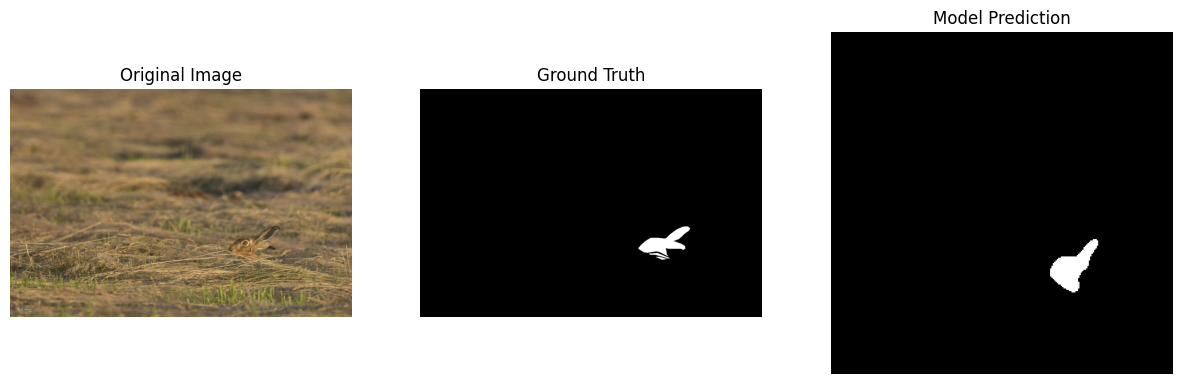

In [80]:
import matplotlib.pyplot as plt

image_name = os.listdir("/content/COD10K/COD10K-v3/Test/Image")[0]
image_path = "/content/COD10K/COD10K-v3/Test/Image/" + image_name
mask_path = "/content/COD10K/COD10K-v3/Test/GT_Object/" + os.path.splitext(image_name)[0] + ".png"

original = Image.open(image_path).convert("RGB")
ground_truth = Image.open(mask_path).convert("L")

with torch.no_grad():
    output = torch.sigmoid(attention_model(transform(original).unsqueeze(0).to(device)))

predicted = (output.squeeze().cpu().numpy() > 0.5).astype("uint8")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted, cmap="gray")
plt.title("Model Prediction")
plt.axis("off")

plt.show()

Ground truth foreground: 0.9 %
Predicted foreground: 0.99 %


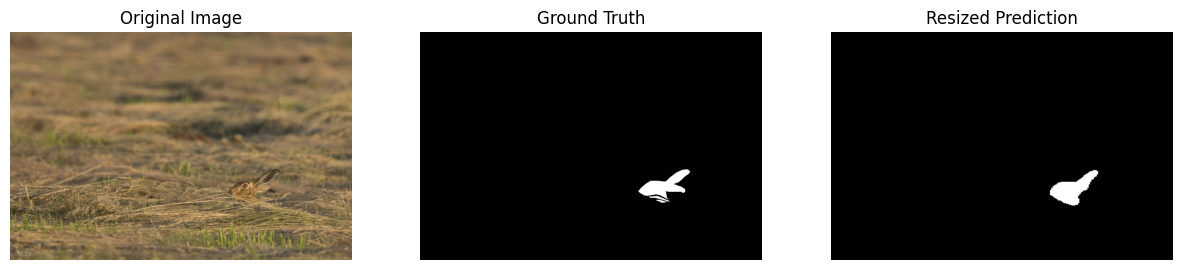

In [81]:
# Resize prediction to the original image dimensions
predicted_resized = Image.fromarray(predicted * 255)
predicted_resized = predicted_resized.resize(
    original.size, Image.Resampling.NEAREST
)

ground_truth_array = np.array(ground_truth) > 0
prediction_array = np.array(predicted_resized) > 127

print("Ground truth foreground:",
      round(ground_truth_array.mean() * 100, 2), "%")

print("Predicted foreground:",
      round(prediction_array.mean() * 100, 2), "%")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ground_truth_array, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction_array, cmap="gray")
plt.title("Resized Prediction")
plt.axis("off")

plt.show()

In [82]:
intersection = np.logical_and(
    prediction_array, ground_truth_array
).sum()

union = np.logical_or(
    prediction_array, ground_truth_array
).sum()

iou = intersection / (union + 1e-8)

print(f"Single-image IoU: {iou:.4f}")
print(f"Single-image IoU: {iou * 100:.2f}%")

Single-image IoU: 0.7035
Single-image IoU: 70.35%


In [83]:
def predict_image(image):
    if image is None:
        return None, None

    original = image.convert("RGB")
    input_tensor = transform(original).unsqueeze(0).to(device)

    attention_model.eval()

    with torch.no_grad():
        output = torch.sigmoid(attention_model(input_tensor))

    mask = (output.squeeze().cpu().numpy() > 0.5).astype(np.uint8) * 255

    mask_image = Image.fromarray(mask).resize(
        original.size, Image.Resampling.NEAREST
    )

    # Create a red overlay for detected objects
    original_array = np.array(original).copy()
    mask_array = np.array(mask_image) > 0

    overlay = original_array.copy()
    overlay[mask_array] = (
        0.5 * original_array[mask_array] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    return mask_image, Image.fromarray(overlay)


demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Upload an Image"),
    outputs=[
        gr.Image(type="pil", label="Segmentation Mask"),
        gr.Image(type="pil", label="Detected Object Overlay")
    ],
    title="CityCare Hospital - Camouflaged Object Detection",
    description="Upload an image to detect camouflaged objects using Res2Net + CBAM."
)

print("Improved Gradio interface created successfully!")

Improved Gradio interface created successfully!


In [91]:
demo.launch(share=True, debug=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://72de86b5b582d0533e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


KeyboardInterrupt: 

In [87]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/huggingface_demo"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder created:", PROJECT_DIR)

Project folder created: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/huggingface_demo


In [89]:
import shutil
import os

source = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/res2net_attention_finetuned.pth"

destination = os.path.join(PROJECT_DIR, "best_model.pth")

shutil.copy2(source, destination)

print("Model copied successfully!")
print("Model size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")

Model copied successfully!
Model size: 168.54 MB


In [90]:
import inspect

for cls in [ConvBlock, ChannelAttention, SpatialAttention, CBAM, DecoderBlock, Res2NetCOD]:
    print(f"\n{'='*50}")
    print(inspect.getsource(cls))

OSError: source code not available

In [92]:
print(attention_model)

Res2NetCOD(
  (encoder): FeatureListNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottle2neck(
        (conv1): Conv2d(64, 104, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(104, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (convs): ModuleList(
          (0-2): 3 x Conv2d(26, 26, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        )
        (bns): ModuleList(
          (0-2): 3 x BatchNorm2d(26, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
        (drop_block): Identity()
        (pool): AvgPool2d(kernel_size=3, stride=1, padding=1)
        (conv3): Conv2d(104

In [94]:
print("Model class:", type(attention_model).__name__)

print("\nMODEL COMPONENTS:")
for name, module in attention_model.named_children():
    print(f"\n{name}: {type(module).__name__}")
    print(module)

print("\nTOTAL PARAMETERS:",
      sum(p.numel() for p in attention_model.parameters()))

Model class: Res2NetCOD

MODEL COMPONENTS:

encoder: FeatureListNet
FeatureListNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act1): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottle2neck(
      (conv1): Conv2d(64, 104, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(104, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (convs): ModuleList(
        (0-2): 3 x Conv2d(26, 26, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (bns): ModuleList(
        (0-2): 3 x BatchNorm2d(26, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (drop_block): Identity()
      (pool): AvgPool2d(kernel_size=3, stride=1, padding=1)
      (conv3): C

In [95]:
checkpoint = torch.load(
    "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/models/res2net_attention_finetuned.pth",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())

print("\nModel layer names and shapes:")
for name, tensor in checkpoint["model_state_dict"].items():
    print(name, tuple(tensor.shape))

Checkpoint keys: dict_keys(['model_state_dict', 'training_history'])

Model layer names and shapes:
encoder.conv1.weight (64, 3, 7, 7)
encoder.bn1.weight (64,)
encoder.bn1.bias (64,)
encoder.bn1.running_mean (64,)
encoder.bn1.running_var (64,)
encoder.bn1.num_batches_tracked ()
encoder.layer1.0.conv1.weight (104, 64, 1, 1)
encoder.layer1.0.bn1.weight (104,)
encoder.layer1.0.bn1.bias (104,)
encoder.layer1.0.bn1.running_mean (104,)
encoder.layer1.0.bn1.running_var (104,)
encoder.layer1.0.bn1.num_batches_tracked ()
encoder.layer1.0.convs.0.weight (26, 26, 3, 3)
encoder.layer1.0.convs.1.weight (26, 26, 3, 3)
encoder.layer1.0.convs.2.weight (26, 26, 3, 3)
encoder.layer1.0.bns.0.weight (26,)
encoder.layer1.0.bns.0.bias (26,)
encoder.layer1.0.bns.0.running_mean (26,)
encoder.layer1.0.bns.0.running_var (26,)
encoder.layer1.0.bns.0.num_batches_tracked ()
encoder.layer1.0.bns.1.weight (26,)
encoder.layer1.0.bns.1.bias (26,)
encoder.layer1.0.bns.1.running_mean (26,)
encoder.layer1.0.bns.1.running

In [96]:
state = checkpoint["model_state_dict"]

print("Total checkpoint tensors:", len(state))

print("\nFirst 30 layer names:")
for name in list(state.keys())[:30]:
    print(name)

print("\nModel component prefixes:")
prefixes = sorted(set(name.split(".")[0] for name in state.keys()))
print(prefixes)

Total checkpoint tensors: 579

First 30 layer names:
encoder.conv1.weight
encoder.bn1.weight
encoder.bn1.bias
encoder.bn1.running_mean
encoder.bn1.running_var
encoder.bn1.num_batches_tracked
encoder.layer1.0.conv1.weight
encoder.layer1.0.bn1.weight
encoder.layer1.0.bn1.bias
encoder.layer1.0.bn1.running_mean
encoder.layer1.0.bn1.running_var
encoder.layer1.0.bn1.num_batches_tracked
encoder.layer1.0.convs.0.weight
encoder.layer1.0.convs.1.weight
encoder.layer1.0.convs.2.weight
encoder.layer1.0.bns.0.weight
encoder.layer1.0.bns.0.bias
encoder.layer1.0.bns.0.running_mean
encoder.layer1.0.bns.0.running_var
encoder.layer1.0.bns.0.num_batches_tracked
encoder.layer1.0.bns.1.weight
encoder.layer1.0.bns.1.bias
encoder.layer1.0.bns.1.running_mean
encoder.layer1.0.bns.1.running_var
encoder.layer1.0.bns.1.num_batches_tracked
encoder.layer1.0.bns.2.weight
encoder.layer1.0.bns.2.bias
encoder.layer1.0.bns.2.running_mean
encoder.layer1.0.bns.2.running_var
encoder.layer1.0.bns.2.num_batches_tracked

Mode

In [97]:
for component in ["decoder1", "decoder2", "decoder3", "decoder4"]:
    print(f"\n--- {component} ---")

    names = [
        name for name in state.keys()
        if name.startswith(component + ".")
    ]

    for name in names[:20]:
        print(name, tuple(state[name].shape))


--- decoder1 ---
decoder1.conv.block.0.weight (512, 3072, 3, 3)
decoder1.conv.block.1.weight (512,)
decoder1.conv.block.1.bias (512,)
decoder1.conv.block.1.running_mean (512,)
decoder1.conv.block.1.running_var (512,)
decoder1.conv.block.1.num_batches_tracked ()
decoder1.conv.block.3.weight (512, 512, 3, 3)
decoder1.conv.block.4.weight (512,)
decoder1.conv.block.4.bias (512,)
decoder1.conv.block.4.running_mean (512,)
decoder1.conv.block.4.running_var (512,)
decoder1.conv.block.4.num_batches_tracked ()
decoder1.attention.channel_attention.mlp.0.weight (32, 512, 1, 1)
decoder1.attention.channel_attention.mlp.2.weight (512, 32, 1, 1)
decoder1.attention.spatial_attention.conv.weight (1, 2, 7, 7)

--- decoder2 ---
decoder2.conv.block.0.weight (256, 1024, 3, 3)
decoder2.conv.block.1.weight (256,)
decoder2.conv.block.1.bias (256,)
decoder2.conv.block.1.running_mean (256,)
decoder2.conv.block.1.running_var (256,)
decoder2.conv.block.1.num_batches_tracked ()
decoder2.conv.block.3.weight (256, 2

In [98]:
for component in ["decoder1", "decoder2", "decoder3", "decoder4"]:
    print(f"\n{component} attention layers:")

    for name in state.keys():
        if name.startswith(component + ".attention."):
            print(name, tuple(state[name].shape))


decoder1 attention layers:
decoder1.attention.channel_attention.mlp.0.weight (32, 512, 1, 1)
decoder1.attention.channel_attention.mlp.2.weight (512, 32, 1, 1)
decoder1.attention.spatial_attention.conv.weight (1, 2, 7, 7)

decoder2 attention layers:
decoder2.attention.channel_attention.mlp.0.weight (16, 256, 1, 1)
decoder2.attention.channel_attention.mlp.2.weight (256, 16, 1, 1)
decoder2.attention.spatial_attention.conv.weight (1, 2, 7, 7)

decoder3 attention layers:
decoder3.attention.channel_attention.mlp.0.weight (8, 128, 1, 1)
decoder3.attention.channel_attention.mlp.2.weight (128, 8, 1, 1)
decoder3.attention.spatial_attention.conv.weight (1, 2, 7, 7)

decoder4 attention layers:
decoder4.attention.channel_attention.mlp.0.weight (8, 64, 1, 1)
decoder4.attention.channel_attention.mlp.2.weight (64, 8, 1, 1)
decoder4.attention.spatial_attention.conv.weight (1, 2, 7, 7)


In [99]:
print("Encoder layer names and shapes:\n")

encoder_keys = [
    (name, tensor.shape)
    for name, tensor in state.items()
    if name.startswith("encoder.")
]

for name, shape in encoder_keys[:15]:
    print(name, tuple(shape))

print("\nTotal encoder tensors:", len(encoder_keys))

print("\nTimm version:")
import timm
print(timm.__version__)

Encoder layer names and shapes:

encoder.conv1.weight (64, 3, 7, 7)
encoder.bn1.weight (64,)
encoder.bn1.bias (64,)
encoder.bn1.running_mean (64,)
encoder.bn1.running_var (64,)
encoder.bn1.num_batches_tracked ()
encoder.layer1.0.conv1.weight (104, 64, 1, 1)
encoder.layer1.0.bn1.weight (104,)
encoder.layer1.0.bn1.bias (104,)
encoder.layer1.0.bn1.running_mean (104,)
encoder.layer1.0.bn1.running_var (104,)
encoder.layer1.0.bn1.num_batches_tracked ()
encoder.layer1.0.convs.0.weight (26, 26, 3, 3)
encoder.layer1.0.convs.1.weight (26, 26, 3, 3)
encoder.layer1.0.convs.2.weight (26, 26, 3, 3)

Total encoder tensors: 510

Timm version:
1.0.31


In [102]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3/huggingface_demo"

os.chdir(PROJECT_DIR)

print("Current folder:", os.getcwd())

Current folder: /content/drive/MyDrive/Colab Notebooks/COD10K/Task3/huggingface_demo


In [103]:
%%writefile app.py

import gradio as gr
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import numpy as np
from PIL import Image
from torchvision import transforms


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class ChannelAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        hidden = max(8, channels // 16)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False)
        )

    def forward(self, x):
        avg = F.adaptive_avg_pool2d(x, 1)
        mx = F.adaptive_max_pool2d(x, 1)
        return x * torch.sigmoid(self.mlp(avg) + self.mlp(mx))


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, 7, padding=3, bias=False)

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx = torch.max(x, dim=1, keepdim=True)[0]
        attention = torch.sigmoid(
            self.conv(torch.cat([avg, mx], dim=1))
        )
        return x * attention


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel_attention = ChannelAttention(channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):
        return self.spatial_attention(self.channel_attention(x))


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, use_attention=True, dropout=0):
        super().__init__()
        self.conv = ConvBlock(in_channels, out_channels)
        self.attention = CBAM(out_channels) if use_attention else nn.Identity()

    def forward(self, x, skip):
        x = F.interpolate(
            x, size=skip.shape[2:],
            mode="bilinear", align_corners=False
        )
        x = torch.cat([x, skip], dim=1)
        return self.attention(self.conv(x))


class Res2NetCOD(nn.Module):
    def __init__(self, use_attention=True):
        super().__init__()

        self.encoder = timm.create_model(
            "res2net50_26w_4s",
            pretrained=False,
            features_only=True
        )

        self.decoder1 = DecoderBlock(3072, 512, use_attention, 16)
        self.decoder2 = DecoderBlock(1024, 256, use_attention, 16)
        self.decoder3 = DecoderBlock(512, 128, use_attention, 16)
        self.decoder4 = DecoderBlock(192, 64, use_attention, 8)

        self.final = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        input_size = x.shape[2:]
        features = self.encoder(x)

        x = self.decoder1(features[4], features[3])
        x = self.decoder2(x, features[2])
        x = self.decoder3(x, features[1])
        x = self.decoder4(x, features[0])

        x = self.final(x)

        return F.interpolate(
            x, size=input_size,
            mode="bilinear", align_corners=False
        )


# Load trained checkpoint
model = Res2NetCOD(use_attention=True)

checkpoint = torch.load(
    "best_model.pth",
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(device)
model.eval()


transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def predict_image(image):
    if image is None:
        return None, None

    original = image.convert("RGB")
    tensor = transform(original).unsqueeze(0).to(device)

    with torch.no_grad():
        output = torch.sigmoid(model(tensor))

    mask = (output.squeeze().cpu().numpy() > 0.5).astype(np.uint8) * 255

    mask_image = Image.fromarray(mask).resize(
        original.size, Image.Resampling.NEAREST
    )

    original_array = np.array(original)
    mask_array = np.array(mask_image) > 0

    overlay = original_array.copy()
    overlay[mask_array] = (
        0.5 * original_array[mask_array] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    return mask_image, Image.fromarray(overlay)


demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Upload an Image"),
    outputs=[
        gr.Image(type="pil", label="Segmentation Mask"),
        gr.Image(type="pil", label="Detected Object Overlay")
    ],
    title="CityCare Hospital - Camouflaged Object Detection",
    description="Res2Net-50 with CBAM attention for camouflaged object detection."
)


if __name__ == "__main__":
    demo.launch()

Writing app.py


In [104]:
import app

print("Model architecture:", type(app.model).__name__)
print("Device:", next(app.model.parameters()).device)
print("Total parameters:", sum(p.numel() for p in app.model.parameters()))
print("Checkpoint loaded successfully!")

Model architecture: Res2NetCOD
Device: cuda:0
Total parameters: 44065873
Checkpoint loaded successfully!


In [105]:
from PIL import Image
import os

test_folder = "/content/COD10K/COD10K-v3/Test/Image"
test_image_name = os.listdir(test_folder)[0]

test_image = Image.open(
    os.path.join(test_folder, test_image_name)
).convert("RGB")

mask, overlay = app.predict_image(test_image)

print("Test image:", test_image_name)
print("Mask size:", mask.size)
print("Overlay size:", overlay.size)
print("Prediction successful!")

Test image: COD10K-CAM-2-Terrestrial-40-Rabbit-2360.jpg
Mask size: (1023, 682)
Overlay size: (1023, 682)
Prediction successful!


In [106]:
%%writefile requirements.txt
torch
torchvision
timm==1.0.31
gradio==6.31.0
numpy
Pillow

Writing requirements.txt


In [107]:
%%writefile README.md
---
title: CityCare Camouflaged Object Detection
emoji: 🏥
colorFrom: blue
colorTo: green
sdk: gradio
sdk_version: 6.31.0
app_file: app.py
pinned: false
---

# CityCare Hospital - Camouflaged Object Detection

An attention-based camouflaged object detection system using Res2Net-50 and CBAM attention.

## Features
- Upload an image for prediction.
- Generate a segmentation mask.
- Display a red overlay of detected regions.

## Model
Res2Net-50 backbone with CBAM attention, trained on the COD10K dataset.

## Run locally
```bash
pip install -r requirements.txt
python app.py

Writing README.md


In [109]:
import os

for file in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, file)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{file} — {size_mb:.2f} MB")

best_model.pth — 168.54 MB
app.py — 0.00 MB
__pycache__ — 0.00 MB
requirements.txt — 0.00 MB
README.md — 0.00 MB


In [1]:
!pip install -U huggingface_hub

In [2]:
from huggingface_hub import notebook_login

notebook_login()

In [5]:
import os

TASK_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3"

for folder, subfolders, files in os.walk(TASK_DIR):
    level = folder.replace(TASK_DIR, "").count(os.sep)
    print("  " * level + os.path.basename(folder) + "/")
    for file in files:
        print("  " * (level + 1) + file)

Task3/
  models/
    res2net_baseline_best.pth
    res2net_attention_best.pth
    res2net_baseline_finetuned.pth
    res2net_attention_finetuned.pth
    resnet50_attention_best.pth
  results/
    task3_model_comparison.csv
  huggingface_demo/
    best_model.pth
    app.py
    requirements.txt
    README.md
    __pycache__/
      app.cpython-313.pyc


In [6]:
import os

TASK_DIR = "/content/drive/MyDrive/Colab Notebooks/COD10K/Task3"

print("MODEL SIZES:")
for file in os.listdir(os.path.join(TASK_DIR, "models")):
    path = os.path.join(TASK_DIR, "models", file)
    print(f"{file}: {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nNOTEBOOK CHECK:")
notebook = "/content/drive/MyDrive/Colab Notebooks/task3_attention_cod_res2net.ipynb"
print("Notebook exists:", os.path.exists(notebook))

MODEL SIZES:
res2net_baseline_best.pth: 504.45 MB
res2net_attention_best.pth: 504.98 MB
res2net_baseline_finetuned.pth: 168.36 MB
res2net_attention_finetuned.pth: 168.54 MB
resnet50_attention_best.pth: 167.91 MB

NOTEBOOK CHECK:
Notebook exists: True
